# Mahurangi High-Water-Risk Classification

This notebook reconstructs and validates the Mahurangi hourly dataset, defines a 24-hour high-water-risk target, engineers hydrological features, and compares Random Forest and XGBoost classifiers using chronological training, validation, and test periods.

## 1. Data Loading and Station Audit

In [1]:
# Import libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

In [2]:
# Load datasets 
file_paths = {
    "rain_primary": r"C:/Users\kgeet\Downloads\644616.csv",
    "rain_support": r"C:/Users\kgeet\Downloads\644626.csv",

    "discharge_primary": r"C:\Users\kgeet\Downloads\6863 (1).csv",
    "discharge_support": r"C:\Users\kgeet\Downloads\6806 (1).csv",

    "level_primary": r"C:\Users\kgeet\Downloads\6863 (2).csv",
    "level_support": r"C:\Users\kgeet\Downloads\6806 (2).csv"
}

In [3]:
def load_gauge_data(file_path, value_name):
    # Read the file while skipping the descriptive first line
    df = pd.read_csv(file_path, skiprows=1)

    # Check the file for the expected three columns
    if df.shape[1] != 3:
        raise ValueError(
            f"{file_path} contains {df.shape[1]} columns instead of 3."
        )

    # Give every dataset consistent column names
    df.columns = ["timestamp", "interval_end", value_name]

    # Convert timestamp columns into datetime format
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        errors="coerce"
    )

    df["interval_end"] = pd.to_datetime(
        df["interval_end"],
        errors="coerce"
    )

    # Convert the measurement column into numbers
    df[value_name] = pd.to_numeric(
        df[value_name],
        errors="coerce"
    )

    # Put the observations in chronological order
    df = df.sort_values("timestamp").reset_index(drop=True)

    return df

In [4]:
rain_primary = load_gauge_data(
    file_paths["rain_primary"],
    "rainfall_mm"
)

rain_support = load_gauge_data(
    file_paths["rain_support"],
    "rainfall_mm"
)

discharge_primary = load_gauge_data(
    file_paths["discharge_primary"],
    "discharge_m3s"
)

discharge_support = load_gauge_data(
    file_paths["discharge_support"],
    "discharge_m3s"
)

level_primary = load_gauge_data(
    file_paths["level_primary"],
    "water_level_m"
)

level_support = load_gauge_data(
    file_paths["level_support"],
    "water_level_m"
)

In [5]:
datasets = {
    "Rainfall primary - 644616": rain_primary,
    "Rainfall support - 644626": rain_support,
    "Discharge primary - 6863": discharge_primary,
    "Discharge support - 6806": discharge_support,
    "Water level primary - 6863": level_primary,
    "Water level support - 6806": level_support
}

for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print(f"Shape: {df.shape}")
    print(f"Beginning: {df['timestamp'].min()}")
    print(f"Ending: {df['timestamp'].max()}")
    print(f"Duplicate timestamps: {df['timestamp'].duplicated().sum()}")
    print(f"Invalid timestamps: {df['timestamp'].isna().sum()}")
    print()
    print(df.head())
    print()

Rainfall primary - 644616
Shape: (96442, 3)
Beginning: 2015-01-01 01:00:00
Ending: 2026-01-01 00:00:00
Duplicate timestamps: 10
Invalid timestamps: 0

            timestamp interval_end  rainfall_mm
0 2015-01-01 01:00:00          NaT        0.000
1 2015-01-01 02:00:00          NaT        0.000
2 2015-01-01 03:00:00          NaT        1.250
3 2015-01-01 04:00:00          NaT        1.240
4 2015-01-01 05:00:00          NaT        0.000

Rainfall support - 644626
Shape: (96442, 3)
Beginning: 2015-01-01 01:00:00
Ending: 2026-01-01 00:00:00
Duplicate timestamps: 10
Invalid timestamps: 0

            timestamp interval_end  rainfall_mm
0 2015-01-01 01:00:00          NaT        0.000
1 2015-01-01 02:00:00          NaT        0.500
2 2015-01-01 03:00:00          NaT        2.500
3 2015-01-01 04:00:00          NaT        0.000
4 2015-01-01 05:00:00          NaT        0.000

Discharge primary - 6863
Shape: (101040, 3)
Beginning: 2015-01-01 00:00:00
Ending: 2026-07-11 23:00:00
Duplicate timesta

In [6]:
audit_results = []

for name, df in datasets.items():
    value_column = df.columns[2]

    audit_results.append({
        "dataset": name,
        "rows": len(df),
        "start": df["timestamp"].min(),
        "end": df["timestamp"].max(),
        "valid_values": df[value_column].notna().sum(),
        "missing_values": df[value_column].isna().sum(),
        "missing_percent": df[value_column].isna().mean() * 100,
        "duplicate_timestamps": df["timestamp"].duplicated().sum(),
        "negative_values": (df[value_column] < 0).sum(),
        "minimum": df[value_column].min(),
        "maximum": df[value_column].max()
    })

audit_table = pd.DataFrame(audit_results)
audit_table

,dataset,rows,start,end,valid_values,missing_values,missing_percent,duplicate_timestamps,negative_values,minimum,maximum
0,Rainfall primary - 644616,96442,2015-01-01 01:00:00,2026-01-01 00:00:00,95554,888,0.921,10,0,0.000,43.660
1,Rainfall support - 644626,96442,2015-01-01 01:00:00,2026-01-01 00:00:00,95703,739,0.766,10,0,0.000,47.201
2,Discharge primary - 6863,101040,2015-01-01 00:00:00,2026-07-11 23:00:00,100790,250,0.247,0,0,0.014,247.258
3,Discharge support - 6806,101040,2015-01-01 00:00:00,2026-07-11 23:00:00,34387,66653,65.967,0,0,0.061,102.475
4,Water level primary - 6863,101040,2015-01-01 00:00:00,2026-07-11 23:00:00,100792,248,0.245,0,0,1.177,5.082
5,Water level support - 6806,101040,2015-01-01 00:00:00,2026-07-11 23:00:00,34378,66662,65.976,0,0,0.288,3.132


In [7]:
# Display duplicate timestamps
rain_primary_duplicates = rain_primary[
    rain_primary.duplicated(
        subset="timestamp",
        keep=False
    )
].sort_values("timestamp")

rain_support_duplicates = rain_support[
    rain_support.duplicated(
        subset="timestamp",
        keep=False
    )
].sort_values("timestamp")

print("644616 primary rainfall duplicates:")
display(rain_primary_duplicates)

print("\n644626 supporting rainfall duplicates:")
display(rain_support_duplicates)

644616 primary rainfall duplicates:


,timestamp,interval_end,rainfall_mm
8759,2016-01-01,NaT,0.000
8760,2016-01-01,NaT,NaN
17544,2017-01-01,NaT,0.000
17545,2017-01-01,NaT,NaN
26305,2018-01-01,NaT,0.000
26306,2018-01-01,NaT,NaN
35066,2019-01-01,NaT,NaN
35067,2019-01-01,NaT,NaN
43828,2020-01-01,NaT,0.000
43827,2020-01-01,NaT,NaN



644626 supporting rainfall duplicates:


,timestamp,interval_end,rainfall_mm
8759,2016-01-01,NaT,0.039
8760,2016-01-01,NaT,NaN
17544,2017-01-01,NaT,0.004
17545,2017-01-01,NaT,NaN
26305,2018-01-01,NaT,0.000
26306,2018-01-01,NaT,NaN
35066,2019-01-01,NaT,0.000
35067,2019-01-01,NaT,NaN
43828,2020-01-01,NaT,0.000
43827,2020-01-01,NaT,NaN


## 2. Data Cleaning and Station Integration

In [8]:
# Cell 8 - Resolve rainfall duplicates safely
def resolve_rainfall_duplicates(df):
    # Work on a copy so the original raw dataset remains unchanged
    cleaned = df.copy()

    # Count the number of valid measurements at each timestamp
    valid_counts = cleaned.groupby("timestamp")["rainfall_mm"].count()

    # Safety check: there should not be two conflicting valid measurements
    if valid_counts.max() > 1:
        raise ValueError(
            "At least one timestamp contains multiple valid rainfall values. "
            "These records require manual inspection."
        )

    # Group by timestamp and retain the first non-missing measurement
    cleaned = (
        cleaned
        .groupby("timestamp", as_index=False)
        .agg({
            "rainfall_mm": "first"
        })
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return cleaned

rain_primary_clean = resolve_rainfall_duplicates(rain_primary)
rain_support_clean = resolve_rainfall_duplicates(rain_support)

In [9]:
#Cell 9 - Verify the result
print("Primary rainfall - 644616")
print("Rows before:", len(rain_primary))
print("Rows after:", len(rain_primary_clean))
print(
    "Duplicate timestamps after cleaning:",
    rain_primary_clean["timestamp"].duplicated().sum()
)
print(
    "Missing measurements after cleaning:",
    rain_primary_clean["rainfall_mm"].isna().sum()
)

print("\nSupporting rainfall - 644626")
print("Rows before:", len(rain_support))
print("Rows after:", len(rain_support_clean))
print(
    "Duplicate timestamps after cleaning:",
    rain_support_clean["timestamp"].duplicated().sum()
)
print(
    "Missing measurements after cleaning:",
    rain_support_clean["rainfall_mm"].isna().sum()
)

Primary rainfall - 644616
Rows before: 96442
Rows after: 96432
Duplicate timestamps after cleaning: 0
Missing measurements after cleaning: 878

Supporting rainfall - 644626
Rows before: 96442
Rows after: 96432
Duplicate timestamps after cleaning: 0
Missing measurements after cleaning: 729


In [10]:
#Cell 10 - Merge the two rainfall stations
rainfall_combined = pd.merge(
    rain_primary_clean.rename(
        columns={"rainfall_mm": "rainfall_644616"}
    ),
    rain_support_clean.rename(
        columns={"rainfall_mm": "rainfall_644626"}
    ),
    on="timestamp",
    how="outer",
    validate="one_to_one"
)

rainfall_combined = (
    rainfall_combined
    .sort_values("timestamp")
    .reset_index(drop=True)
)

In [11]:
#Cell 11 - Create the final rainfall variable
# Mark rows where the primary gauge is missing
# but the supporting gauge is available
rainfall_combined["rainfall_substituted"] = (
    rainfall_combined["rainfall_644616"].isna()
    & rainfall_combined["rainfall_644626"].notna()
).astype(int)

# Use primary rainfall first.
# Use supporting rainfall only where primary rainfall is missing.
rainfall_combined["rainfall_mm"] = (
    rainfall_combined["rainfall_644616"]
    .combine_first(rainfall_combined["rainfall_644626"])
)

# Record the source of each final measurement
rainfall_combined["rainfall_source"] = np.select(
    [
        rainfall_combined["rainfall_644616"].notna(),
        rainfall_combined["rainfall_644626"].notna()
    ],
    [
        "644616_primary",
        "644626_support"
    ],
    default="missing"
)

In [12]:
#Cell 12 - Verify the combined rainfall data
print("Combined rainfall rows:", len(rainfall_combined))

print(
    "Duplicate timestamps:",
    rainfall_combined["timestamp"].duplicated().sum()
)

print(
    "Primary rainfall missing:",
    rainfall_combined["rainfall_644616"].isna().sum()
)

print(
    "Supporting rainfall used:",
    rainfall_combined["rainfall_substituted"].sum()
)

print(
    "Final rainfall missing:",
    rainfall_combined["rainfall_mm"].isna().sum()
)

print("\nRainfall source counts:")
print(rainfall_combined["rainfall_source"].value_counts())

display(rainfall_combined.head())

Combined rainfall rows: 96432
Duplicate timestamps: 0
Primary rainfall missing: 878
Supporting rainfall used: 878
Final rainfall missing: 0

Rainfall source counts:
rainfall_source
644616_primary    95554
644626_support      878
Name: count, dtype: int64


,timestamp,rainfall_644616,rainfall_644626,rainfall_substituted,rainfall_mm,rainfall_source
0,2015-01-01 01:00:00,0.000,0.000,0,0.000,644616_primary
1,2015-01-01 02:00:00,0.000,0.500,0,0.000,644616_primary
2,2015-01-01 03:00:00,1.250,2.500,0,1.250,644616_primary
3,2015-01-01 04:00:00,1.240,0.000,0,1.240,644616_primary
4,2015-01-01 05:00:00,0.000,0.000,0,0.000,644616_primary


In [13]:
#Cell 13 - Combine the river datasets
river_combined = (
    discharge_primary[
        ["timestamp", "discharge_m3s"]
    ]
    .rename(
        columns={"discharge_m3s": "discharge_6863"}
    )
    .merge(
        discharge_support[
            ["timestamp", "discharge_m3s"]
        ].rename(
            columns={"discharge_m3s": "discharge_6806"}
        ),
        on="timestamp",
        how="outer",
        validate="one_to_one"
    )
    .merge(
        level_primary[
            ["timestamp", "water_level_m"]
        ].rename(
            columns={"water_level_m": "water_level_6863"}
        ),
        on="timestamp",
        how="outer",
        validate="one_to_one"
    )
    .merge(
        level_support[
            ["timestamp", "water_level_m"]
        ].rename(
            columns={"water_level_m": "water_level_6806"}
        ),
        on="timestamp",
        how="outer",
        validate="one_to_one"
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

In [14]:
#Cell 14 - Check when 6806 can help 6863
print("Combined river rows:", len(river_combined))

print(
    "Duplicate timestamps:",
    river_combined["timestamp"].duplicated().sum()
)

print(
    "\nMissing primary discharge:",
    river_combined["discharge_6863"].isna().sum()
)

print(
    "6806 discharge available when 6863 is missing:",
    (
        river_combined["discharge_6863"].isna()
        & river_combined["discharge_6806"].notna()
    ).sum()
)

print(
    "Both discharge stations missing:",
    (
        river_combined["discharge_6863"].isna()
        & river_combined["discharge_6806"].isna()
    ).sum()
)

print(
    "\nMissing primary water level:",
    river_combined["water_level_6863"].isna().sum()
)

print(
    "6806 water level available when 6863 is missing:",
    (
        river_combined["water_level_6863"].isna()
        & river_combined["water_level_6806"].notna()
    ).sum()
)

print(
    "Both water-level stations missing:",
    (
        river_combined["water_level_6863"].isna()
        & river_combined["water_level_6806"].isna()
    ).sum()
)

display(river_combined.head())

Combined river rows: 101040
Duplicate timestamps: 0

Missing primary discharge: 250
6806 discharge available when 6863 is missing: 144
Both discharge stations missing: 106

Missing primary water level: 248
6806 water level available when 6863 is missing: 144
Both water-level stations missing: 104


,timestamp,discharge_6863,discharge_6806,water_level_6863,water_level_6806
0,2015-01-01 00:00:00,0.328,0.361,1.333,0.587
1,2015-01-01 01:00:00,0.323,0.359,1.332,0.586
2,2015-01-01 02:00:00,0.423,0.440,1.349,0.627
3,2015-01-01 03:00:00,0.461,0.459,1.355,0.635
4,2015-01-01 04:00:00,0.410,0.416,1.347,0.616


In [15]:
#Cell 15 - Fit the station-conversion equations
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [16]:
# Discharge conversion
discharge_overlap = river_combined[
    [
        "discharge_6806",
        "discharge_6863"
    ]
].dropna()

discharge_conversion_model = LinearRegression()

discharge_conversion_model.fit(
    discharge_overlap[["discharge_6806"]],
    discharge_overlap["discharge_6863"]
)

discharge_predictions = discharge_conversion_model.predict(
    discharge_overlap[["discharge_6806"]]
)

print("DISCHARGE CONVERSION")
print("Overlapping observations:", len(discharge_overlap))

print(
    "Equation: discharge_6863 =",
    round(discharge_conversion_model.coef_[0], 6),
    "× discharge_6806 +",
    round(discharge_conversion_model.intercept_, 6)
)

print(
    "R²:",
    round(
        r2_score(
            discharge_overlap["discharge_6863"],
            discharge_predictions
        ),
        4
    )
)

print(
    "MAE:",
    round(
        mean_absolute_error(
            discharge_overlap["discharge_6863"],
            discharge_predictions
        ),
        4
    )
)

DISCHARGE CONVERSION
Overlapping observations: 34243
Equation: discharge_6863 = 1.067553 × discharge_6806 + -0.056217
R²: 0.9921
MAE: 0.0774


In [17]:
# Water-level conversion
level_overlap = river_combined[
    [
        "water_level_6806",
        "water_level_6863"
    ]
].dropna()

level_conversion_model = LinearRegression()

level_conversion_model.fit(
    level_overlap[["water_level_6806"]],
    level_overlap["water_level_6863"]
)

level_predictions = level_conversion_model.predict(
    level_overlap[["water_level_6806"]]
)

print("\nWATER-LEVEL CONVERSION")
print("Overlapping observations:", len(level_overlap))

print(
    "Equation: water_level_6863 =",
    round(level_conversion_model.coef_[0], 6),
    "× water_level_6806 +",
    round(level_conversion_model.intercept_, 6)
)

print(
    "R²:",
    round(
        r2_score(
            level_overlap["water_level_6863"],
            level_predictions
        ),
        4
    )
)

print(
    "MAE:",
    round(
        mean_absolute_error(
            level_overlap["water_level_6863"],
            level_predictions
        ),
        4
    )
)


WATER-LEVEL CONVERSION
Overlapping observations: 34234
Equation: water_level_6863 = 0.708837 × water_level_6806 + 0.936739
R²: 0.8663
MAE: 0.0467


In [18]:
#Cell 16 - Recover missing primary river measurements
river_clean = river_combined.copy()

# Convert all available 6806 discharge values onto the 6863 scale
river_clean["discharge_6806_converted"] = (
    discharge_conversion_model.predict(
        river_clean[["discharge_6806"]].fillna(0)
    )
)

# Converted values should remain missing where 6806 was missing
river_clean.loc[
    river_clean["discharge_6806"].isna(),
    "discharge_6806_converted"
] = np.nan


# Convert all available 6806 water-level values onto the 6863 scale
river_clean["water_level_6806_converted"] = (
    level_conversion_model.predict(
        river_clean[["water_level_6806"]].fillna(0)
    )
)

# Converted values should remain missing where 6806 was missing
river_clean.loc[
    river_clean["water_level_6806"].isna(),
    "water_level_6806_converted"
] = np.nan

In [19]:
#Cell 17 - Create final discharge and water-level variables
# Identify measurements recovered from station 6806
river_clean["discharge_substituted"] = (
    river_clean["discharge_6863"].isna()
    & river_clean["discharge_6806_converted"].notna()
).astype(int)

river_clean["water_level_substituted"] = (
    river_clean["water_level_6863"].isna()
    & river_clean["water_level_6806_converted"].notna()
).astype(int)


# Use 6863 first and converted 6806 only when 6863 is missing
river_clean["discharge_m3s"] = (
    river_clean["discharge_6863"]
    .combine_first(river_clean["discharge_6806_converted"])
)

river_clean["water_level_m"] = (
    river_clean["water_level_6863"]
    .combine_first(river_clean["water_level_6806_converted"])
)

In [20]:
#Cell 18 - Record the source of each measurement
river_clean["discharge_source"] = np.select(
    [
        river_clean["discharge_6863"].notna(),
        river_clean["discharge_6806_converted"].notna()
    ],
    [
        "6863_primary",
        "6806_converted"
    ],
    default="missing"
)

river_clean["water_level_source"] = np.select(
    [
        river_clean["water_level_6863"].notna(),
        river_clean["water_level_6806_converted"].notna()
    ],
    [
        "6863_primary",
        "6806_converted"
    ],
    default="missing"
)

In [21]:
#Cell 19 - Verify the recovery
print("Discharge measurements substituted:")
print(river_clean["discharge_substituted"].sum())

print("Final missing discharge:")
print(river_clean["discharge_m3s"].isna().sum())

print("\nWater-level measurements substituted:")
print(river_clean["water_level_substituted"].sum())

print("Final missing water level:")
print(river_clean["water_level_m"].isna().sum())

print("\nDischarge source counts:")
print(river_clean["discharge_source"].value_counts())

print("\nWater-level source counts:")
print(river_clean["water_level_source"].value_counts())

Discharge measurements substituted:
144
Final missing discharge:
106

Water-level measurements substituted:
144
Final missing water level:
104

Discharge source counts:
discharge_source
6863_primary      100790
6806_converted       144
missing              106
Name: count, dtype: int64

Water-level source counts:
water_level_source
6863_primary      100792
6806_converted       144
missing              104
Name: count, dtype: int64


In [22]:
#Cell 20 - Create the combined Mahurangi base dataset
mahurangi_base = rainfall_combined[
    [
        "timestamp",
        "rainfall_mm",
        "rainfall_substituted",
        "rainfall_source"
    ]
].merge(
    river_clean[
        [
            "timestamp",
            "discharge_m3s",
            "water_level_m",
            "discharge_substituted",
            "water_level_substituted",
            "discharge_source",
            "water_level_source"
        ]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

mahurangi_base = (
    mahurangi_base
    .sort_values("timestamp")
    .reset_index(drop=True)
)

In [23]:
#Cell 21 - Verify the combined dataset
print("Mahurangi base dataset")

print("Rows:", len(mahurangi_base))
print("Beginning:", mahurangi_base["timestamp"].min())
print("Ending:", mahurangi_base["timestamp"].max())

print(
    "Duplicate timestamps:",
    mahurangi_base["timestamp"].duplicated().sum()
)

print("\nMissing values:")
print(
    mahurangi_base[
        [
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m"
        ]
    ].isna().sum()
)

display(mahurangi_base.head())

Mahurangi base dataset
Rows: 96432
Beginning: 2015-01-01 01:00:00
Ending: 2026-01-01 00:00:00
Duplicate timestamps: 0

Missing values:
rainfall_mm       0
discharge_m3s    90
water_level_m    88
dtype: int64


,timestamp,rainfall_mm,rainfall_substituted,rainfall_source,discharge_m3s,water_level_m,discharge_substituted,water_level_substituted,discharge_source,water_level_source
0,2015-01-01 01:00:00,0.000,0,644616_primary,0.323,1.332,0,0,6863_primary,6863_primary
1,2015-01-01 02:00:00,0.000,0,644616_primary,0.423,1.349,0,0,6863_primary,6863_primary
2,2015-01-01 03:00:00,1.250,0,644616_primary,0.461,1.355,0,0,6863_primary,6863_primary
3,2015-01-01 04:00:00,1.240,0,644616_primary,0.410,1.347,0,0,6863_primary,6863_primary
4,2015-01-01 05:00:00,0.000,0,644616_primary,0.374,1.341,0,0,6863_primary,6863_primary


## 3. Data Quality Assessment and Exploratory Analysis

In [24]:
#Cell 22 - Identify consecutive missing-data gaps
def find_missing_runs(df, column):
    missing = df[column].isna()

    # Give each continuous missing/non-missing section an ID
    run_id = missing.ne(missing.shift()).cumsum()

    missing_rows = df.loc[
        missing,
        ["timestamp"]
    ].copy()

    missing_rows["run_id"] = run_id[missing].values

    gap_table = (
        missing_rows
        .groupby("run_id")
        .agg(
            gap_start=("timestamp", "min"),
            gap_end=("timestamp", "max"),
            gap_hours=("timestamp", "size")
        )
        .reset_index(drop=True)
        .sort_values(
            ["gap_hours", "gap_start"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    return gap_table

In [25]:
#Cell 23 - Display discharge and water-level gaps
discharge_gaps = find_missing_runs(
    mahurangi_base,
    "discharge_m3s"
)

water_level_gaps = find_missing_runs(
    mahurangi_base,
    "water_level_m"
)

print("DISCHARGE MISSING-DATA GAPS")
display(discharge_gaps)

print("\nWATER-LEVEL MISSING-DATA GAPS")
display(water_level_gaps)

DISCHARGE MISSING-DATA GAPS


,gap_start,gap_end,gap_hours
0,2024-06-10 00:00:00,2024-06-10 14:00:00,15
1,2022-05-02 09:00:00,2022-05-02 14:00:00,6
2,2018-05-20 06:00:00,2018-05-20 10:00:00,5
3,2025-01-20 10:00:00,2025-01-20 14:00:00,5
4,2022-05-03 09:00:00,2022-05-03 12:00:00,4
5,2023-05-03 10:00:00,2023-05-03 13:00:00,4
6,2022-02-02 09:00:00,2022-02-02 11:00:00,3
7,2024-08-09 11:00:00,2024-08-09 13:00:00,3
8,2024-09-10 10:00:00,2024-09-10 12:00:00,3
9,2020-01-15 08:00:00,2020-01-15 09:00:00,2



WATER-LEVEL MISSING-DATA GAPS


,gap_start,gap_end,gap_hours
0,2024-06-10 00:00:00,2024-06-10 14:00:00,15
1,2018-05-20 06:00:00,2018-05-20 10:00:00,5
2,2022-05-02 09:00:00,2022-05-02 13:00:00,5
3,2025-01-20 10:00:00,2025-01-20 14:00:00,5
4,2022-05-03 09:00:00,2022-05-03 12:00:00,4
5,2023-05-03 10:00:00,2023-05-03 13:00:00,4
6,2022-02-02 09:00:00,2022-02-02 11:00:00,3
7,2024-08-09 11:00:00,2024-08-09 13:00:00,3
8,2024-09-10 10:00:00,2024-09-10 12:00:00,3
9,2020-01-15 08:00:00,2020-01-15 09:00:00,2


In [26]:
#Cell 24 - Add missing-data indicators
mahurangi_preprocessed = mahurangi_base.copy()

mahurangi_preprocessed["discharge_missing"] = (
    mahurangi_preprocessed["discharge_m3s"].isna()
).astype(int)

mahurangi_preprocessed["water_level_missing"] = (
    mahurangi_preprocessed["water_level_m"].isna()
).astype(int)

mahurangi_preprocessed["river_data_missing"] = (
    mahurangi_preprocessed[
        ["discharge_m3s", "water_level_m"]
    ].isna().any(axis=1)
).astype(int)

In [27]:
#Cell 25 - Confirm that the timeline is continuously hourly
time_differences = (
    mahurangi_preprocessed["timestamp"]
    .diff()
    .dropna()
)

print("Expected hourly difference:")
print(pd.Timedelta(hours=1))

print("\nTime-difference counts:")
print(time_differences.value_counts().head())

print(
    "\nNumber of non-hourly timestamp jumps:",
    (time_differences != pd.Timedelta(hours=1)).sum()
)

expected_rows = int(
    (
        mahurangi_preprocessed["timestamp"].max()
        - mahurangi_preprocessed["timestamp"].min()
    ) / pd.Timedelta(hours=1)
) + 1

print("\nExpected number of rows:", expected_rows)
print("Actual number of rows:", len(mahurangi_preprocessed))

Expected hourly difference:
0 days 01:00:00

Time-difference counts:
timestamp
0 days 01:00:00    96431
Name: count, dtype: int64

Number of non-hourly timestamp jumps: 0

Expected number of rows: 96432
Actual number of rows: 96432


In [28]:
#Cell 26 - Distribution and percentile summary
measurement_columns = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]

distribution_summary = (
    mahurangi_preprocessed[measurement_columns]
    .describe(
        percentiles=[
            0.01,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995,
            0.999
        ]
    )
    .T
)

distribution_summary["skewness"] = (
    mahurangi_preprocessed[measurement_columns]
    .skew()
)

display(distribution_summary)

,count,mean,std,min,1%,25%,50%,75%,90%,95%,99%,99.5%,99.9%,max,skewness
rainfall_mm,96432.000,0.177,0.936,0.000,0.000,0.000,0.000,0.000,0.450,0.970,3.940,6.002,12.183,43.660,12.887
discharge_m3s,96342.000,1.380,5.001,0.014,0.023,0.182,0.480,1.043,2.373,4.246,17.605,27.086,69.046,247.258,18.195
water_level_m,96344.000,1.404,0.205,1.177,1.192,1.298,1.359,1.436,1.566,1.717,2.261,2.568,3.469,5.082,4.854


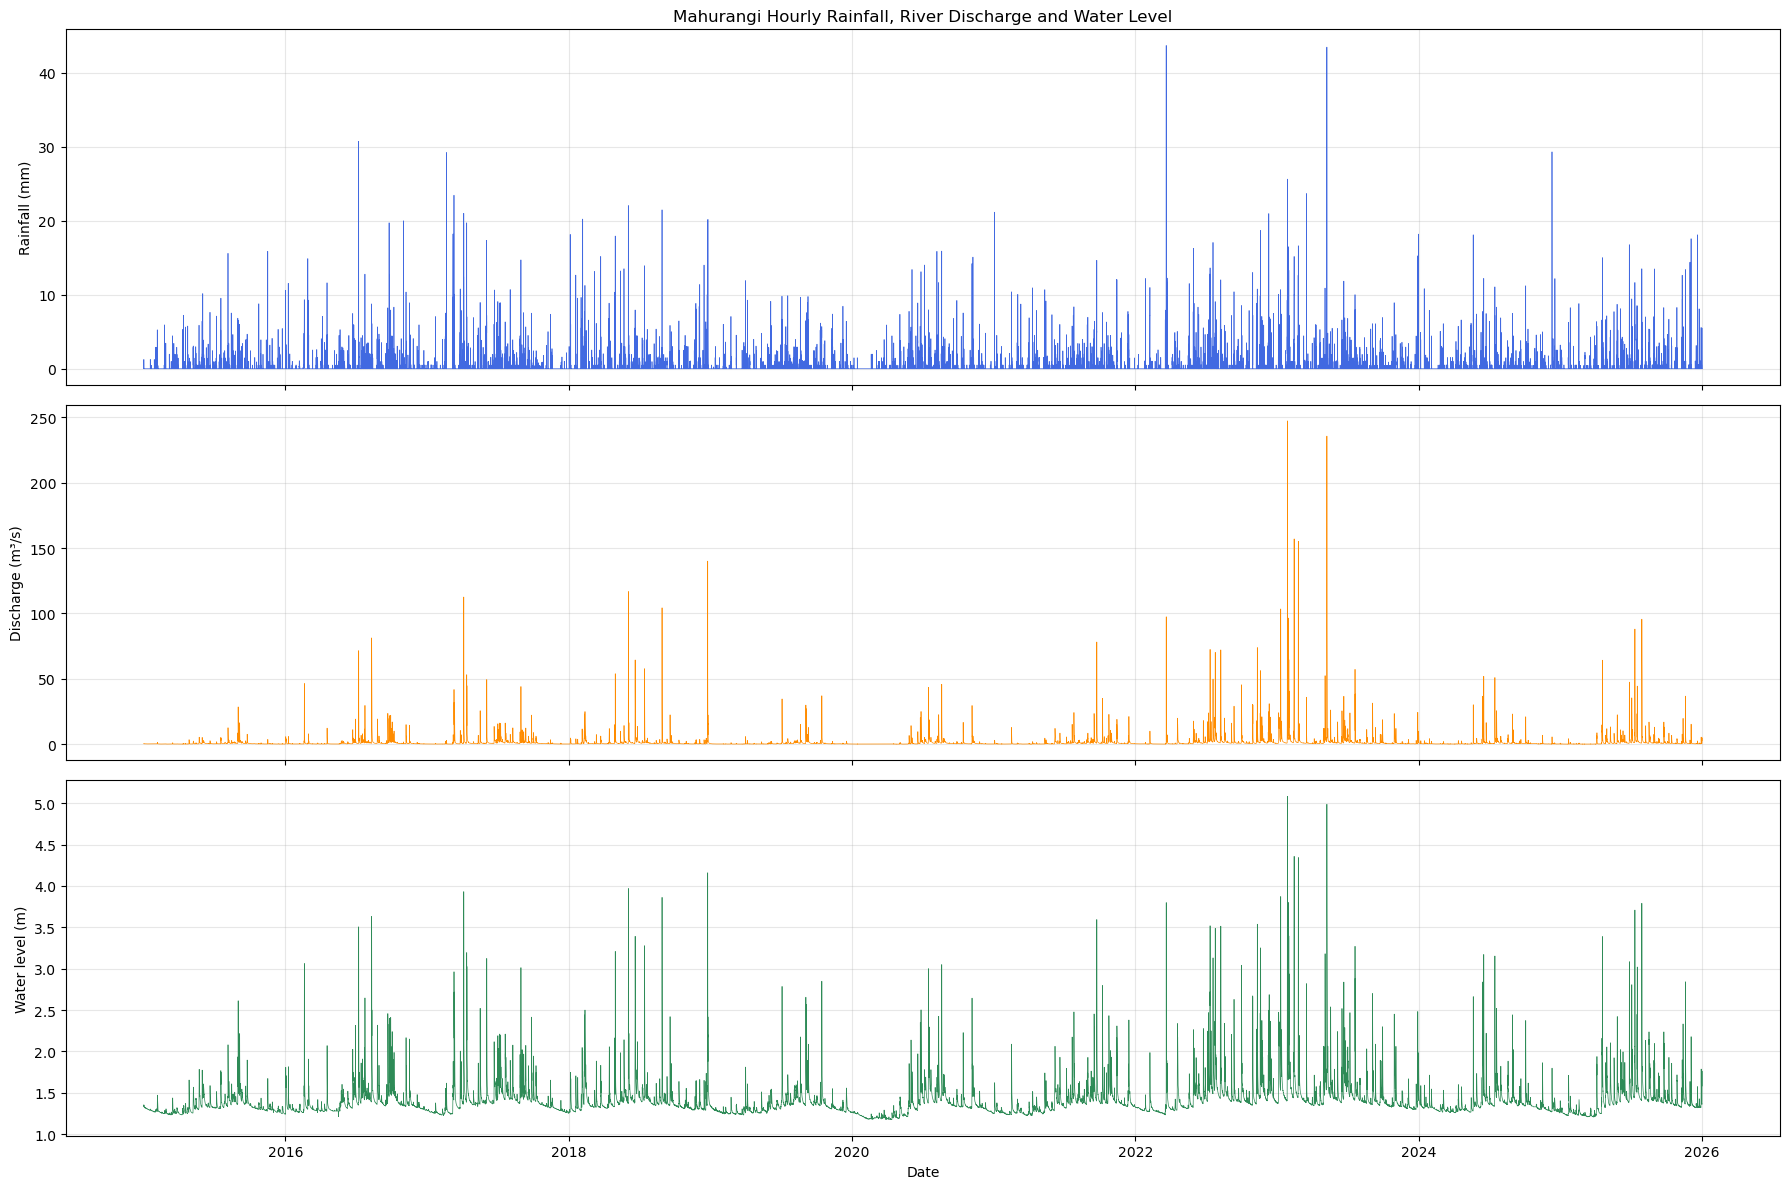

In [29]:
#Cell 27 - Plot the full hourly time series
fig, axes = plt.subplots(
    3,
    1,
    figsize=(18, 12),
    sharex=True
)

# Rainfall
axes[0].plot(
    mahurangi_preprocessed["timestamp"],
    mahurangi_preprocessed["rainfall_mm"],
    color="royalblue",
    linewidth=0.5
)

axes[0].set_title(
    "Mahurangi Hourly Rainfall, River Discharge and Water Level"
)
axes[0].set_ylabel("Rainfall (mm)")
axes[0].grid(alpha=0.3)


# Discharge
axes[1].plot(
    mahurangi_preprocessed["timestamp"],
    mahurangi_preprocessed["discharge_m3s"],
    color="darkorange",
    linewidth=0.5
)

axes[1].set_ylabel("Discharge (m³/s)")
axes[1].grid(alpha=0.3)


# Water level
axes[2].plot(
    mahurangi_preprocessed["timestamp"],
    mahurangi_preprocessed["water_level_m"],
    color="seagreen",
    linewidth=0.5
)

axes[2].set_ylabel("Water level (m)")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
#Cell 28 - Create daily event summaries
event_analysis = (
    mahurangi_preprocessed[
        [
            "timestamp",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m"
        ]
    ]
    .set_index("timestamp")
)

daily_summary = event_analysis.resample("D").agg(
    daily_rainfall_mm=("rainfall_mm", "sum"),
    maximum_discharge_m3s=("discharge_m3s", "max"),
    maximum_water_level_m=("water_level_m", "max")
)

daily_summary.head()

,daily_rainfall_mm,maximum_discharge_m3s,maximum_water_level_m
timestamp,,,
2015-01-01,2.490,0.461,1.355
2015-01-02,0.000,0.307,1.329
2015-01-03,0.000,0.271,1.322
2015-01-04,0.000,0.261,1.320
2015-01-05,0.000,0.280,1.324


In [31]:
#Cell 29 - Display the largest high-water days
top_high_water_days = (
    daily_summary
    .nlargest(15, "maximum_water_level_m")
    .reset_index()
)

display(top_high_water_days)

,timestamp,daily_rainfall_mm,maximum_discharge_m3s,maximum_water_level_m
0,2023-01-27,163.660,247.258,5.082
1,2023-05-09,90.910,235.618,4.986
2,2023-02-14,61.497,156.980,4.357
3,2023-02-24,89.532,155.164,4.342
4,2023-02-25,6.068,148.218,4.282
5,2018-12-24,80.000,139.996,4.158
6,2018-12-25,34.500,122.925,4.022
7,2018-06-03,74.950,116.734,3.968
8,2017-04-04,133.231,112.554,3.930
9,2017-04-05,23.149,109.603,3.905


In [32]:
#Cell 30 - Add previous-day rainfall for validation
daily_summary["previous_day_rainfall_mm"] = (
    daily_summary["daily_rainfall_mm"].shift(1)
)

daily_summary["two_day_rainfall_mm"] = (
    daily_summary["daily_rainfall_mm"]
    + daily_summary["previous_day_rainfall_mm"]
)

top_high_water_days = (
    daily_summary
    .nlargest(15, "maximum_water_level_m")
    .reset_index()
)

display(top_high_water_days)

,timestamp,daily_rainfall_mm,maximum_discharge_m3s,maximum_water_level_m,previous_day_rainfall_mm,two_day_rainfall_mm
0,2023-01-27,163.660,247.258,5.082,2.000,165.660
1,2023-05-09,90.910,235.618,4.986,5.770,96.680
2,2023-02-14,61.497,156.980,4.357,95.223,156.720
3,2023-02-24,89.532,155.164,4.342,0.500,90.032
4,2023-02-25,6.068,148.218,4.282,89.532,95.600
5,2018-12-24,80.000,139.996,4.158,20.000,100.000
6,2018-12-25,34.500,122.925,4.022,80.000,114.500
7,2018-06-03,74.950,116.734,3.968,0.000,74.950
8,2017-04-04,133.231,112.554,3.930,4.430,137.661
9,2017-04-05,23.149,109.603,3.905,133.231,156.380


In [33]:
#Cell 31 - Check discharge and water-level relationship
river_relationship = mahurangi_preprocessed[
    [
        "discharge_m3s",
        "water_level_m"
    ]
].corr(
    method="spearman"
)

print("Spearman correlation:")
display(river_relationship)

Spearman correlation:


,discharge_m3s,water_level_m
discharge_m3s,1.000,1.000
water_level_m,1.000,1.000


In [34]:
#Cell 32 - Prepare seasonal variables
seasonality_data = mahurangi_preprocessed[
    [
        "timestamp",
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ]
].copy()

seasonality_data["month"] = (
    seasonality_data["timestamp"].dt.month
)

seasonality_data["hour"] = (
    seasonality_data["timestamp"].dt.hour
)

seasonality_data["day_of_week"] = (
    seasonality_data["timestamp"].dt.dayofweek
)

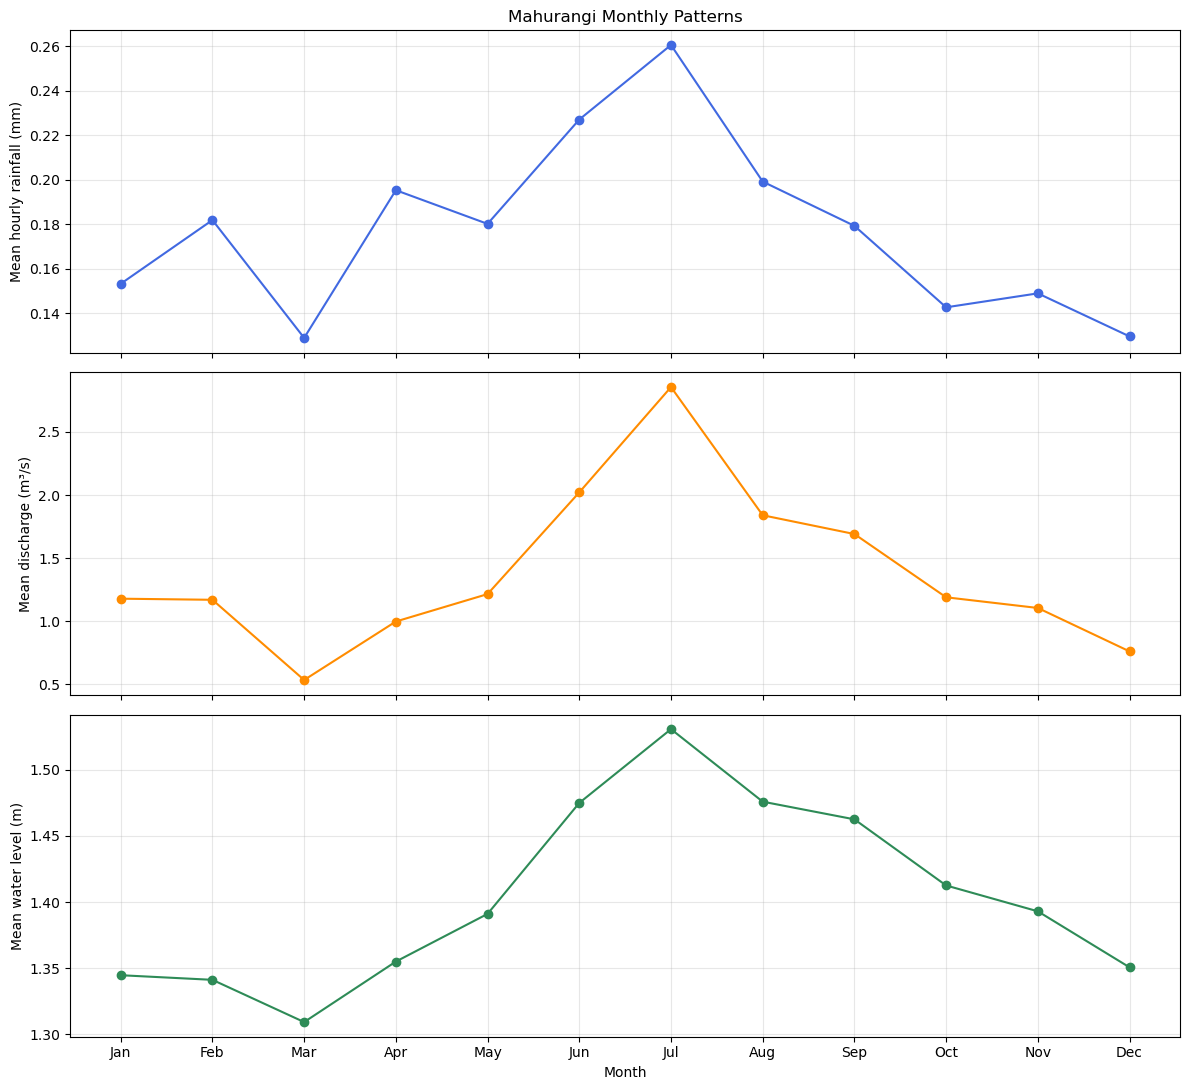

In [35]:
#Cell 33 - Monthly seasonality
monthly_patterns = (
    seasonality_data
    .groupby("month")
    .agg(
        mean_hourly_rainfall=("rainfall_mm", "mean"),
        mean_discharge=("discharge_m3s", "mean"),
        mean_water_level=("water_level_m", "mean")
    )
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 11),
    sharex=True
)

axes[0].plot(
    month_names,
    monthly_patterns["mean_hourly_rainfall"],
    marker="o",
    color="royalblue"
)
axes[0].set_ylabel("Mean hourly rainfall (mm)")
axes[0].set_title("Mahurangi Monthly Patterns")
axes[0].grid(alpha=0.3)

axes[1].plot(
    month_names,
    monthly_patterns["mean_discharge"],
    marker="o",
    color="darkorange"
)
axes[1].set_ylabel("Mean discharge (m³/s)")
axes[1].grid(alpha=0.3)

axes[2].plot(
    month_names,
    monthly_patterns["mean_water_level"],
    marker="o",
    color="seagreen"
)
axes[2].set_ylabel("Mean water level (m)")
axes[2].set_xlabel("Month")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

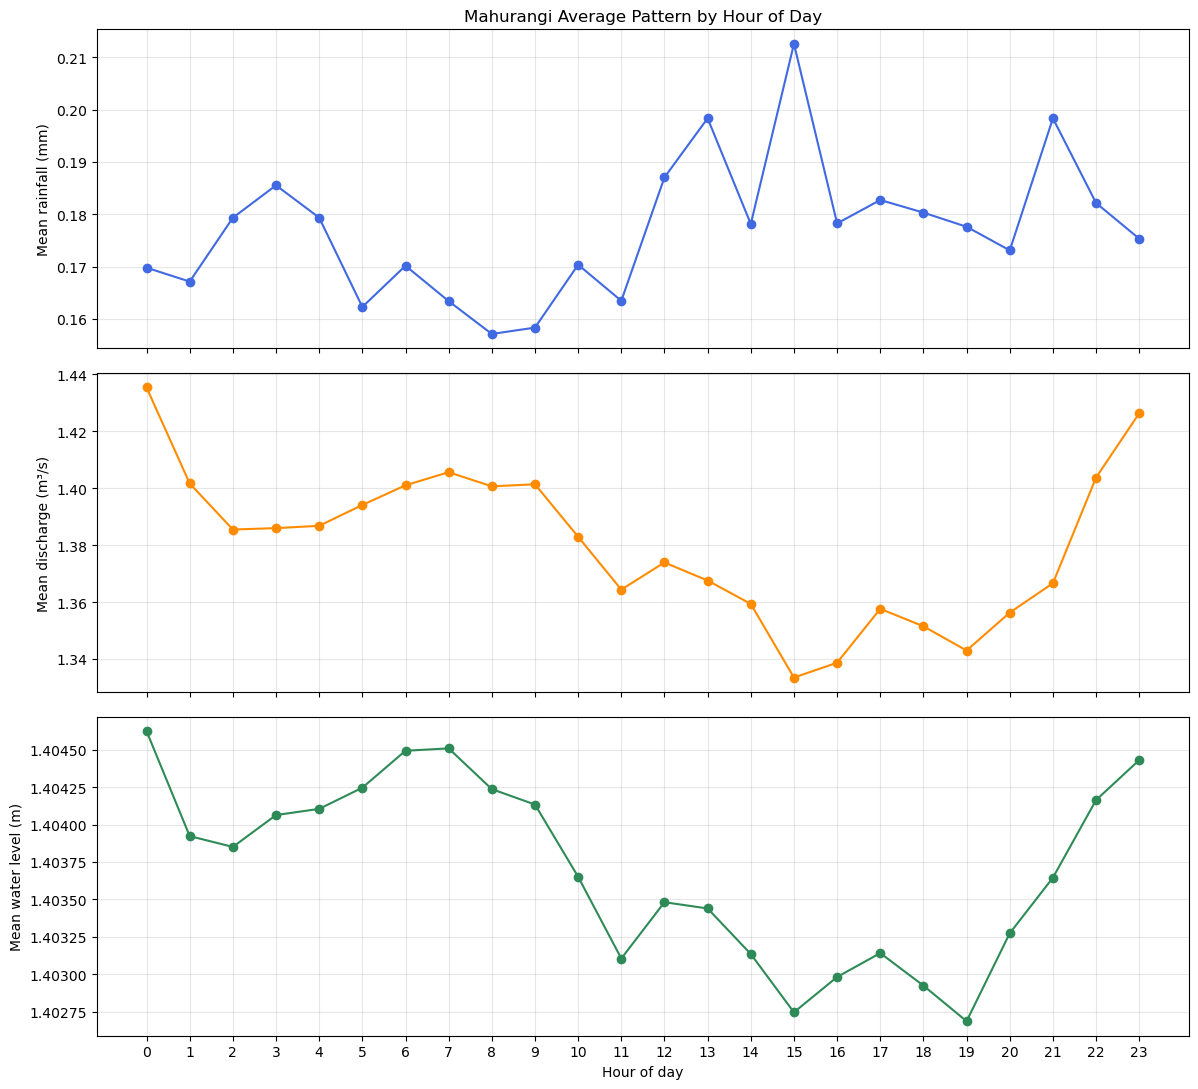

In [36]:
#Cell 34 - Hourly or diurnal pattern
hourly_patterns = (
    seasonality_data
    .groupby("hour")
    .agg(
        mean_rainfall=("rainfall_mm", "mean"),
        mean_discharge=("discharge_m3s", "mean"),
        mean_water_level=("water_level_m", "mean")
    )
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 11),
    sharex=True
)

axes[0].plot(
    hourly_patterns.index,
    hourly_patterns["mean_rainfall"],
    marker="o",
    color="royalblue"
)
axes[0].set_ylabel("Mean rainfall (mm)")
axes[0].set_title("Mahurangi Average Pattern by Hour of Day")
axes[0].grid(alpha=0.3)

axes[1].plot(
    hourly_patterns.index,
    hourly_patterns["mean_discharge"],
    marker="o",
    color="darkorange"
)
axes[1].set_ylabel("Mean discharge (m³/s)")
axes[1].grid(alpha=0.3)

axes[2].plot(
    hourly_patterns.index,
    hourly_patterns["mean_water_level"],
    marker="o",
    color="seagreen"
)
axes[2].set_ylabel("Mean water level (m)")
axes[2].set_xlabel("Hour of day")
axes[2].set_xticks(range(0, 24))
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

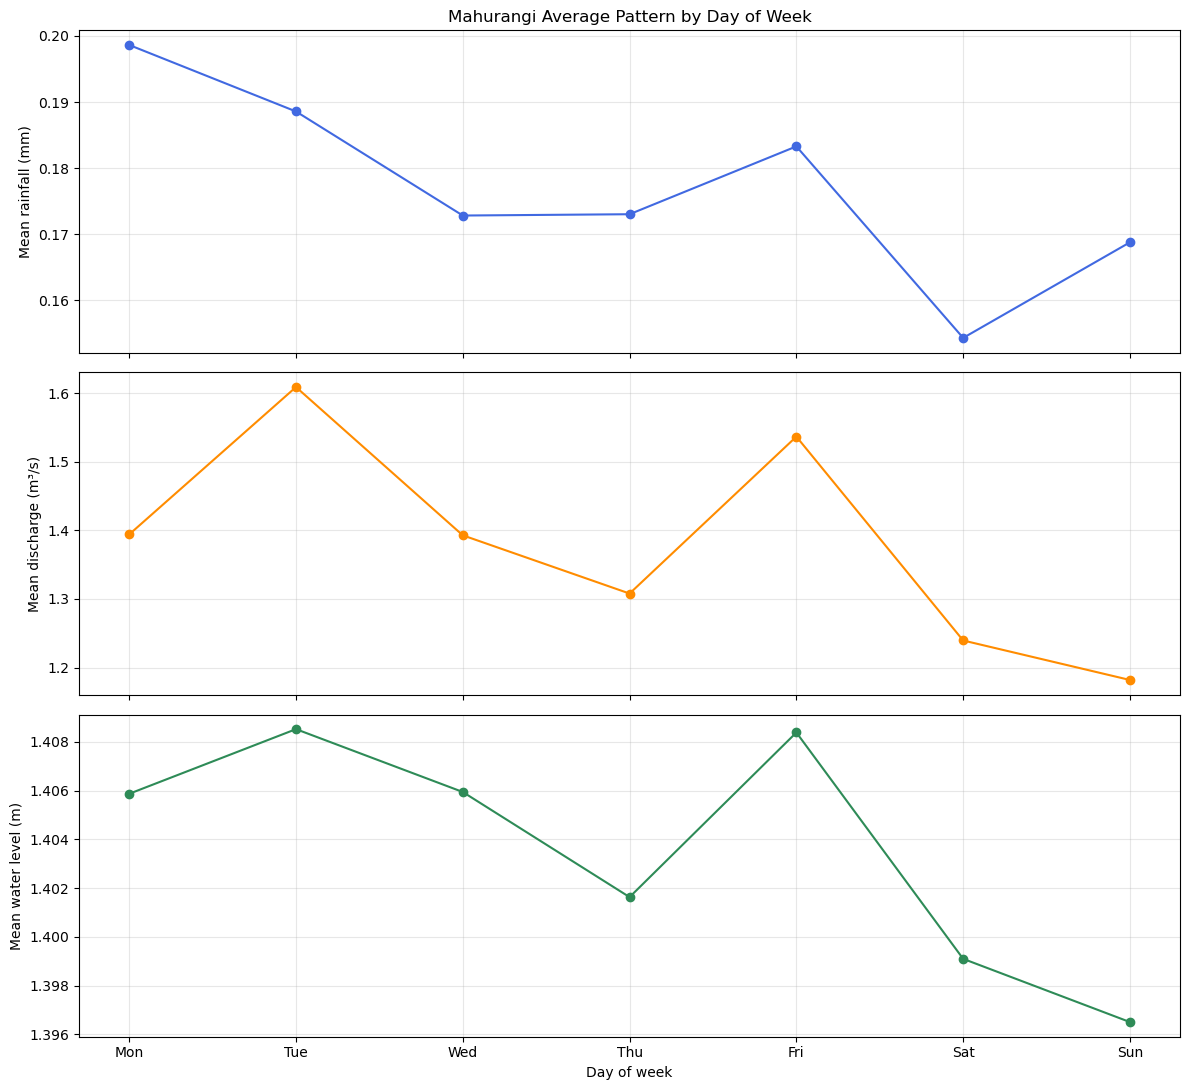

In [37]:
#Cell 35 - Weekly pattern
weekly_patterns = (
    seasonality_data
    .groupby("day_of_week")
    .agg(
        mean_rainfall=("rainfall_mm", "mean"),
        mean_discharge=("discharge_m3s", "mean"),
        mean_water_level=("water_level_m", "mean")
    )
)

day_names = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 11),
    sharex=True
)

axes[0].plot(
    day_names,
    weekly_patterns["mean_rainfall"],
    marker="o",
    color="royalblue"
)
axes[0].set_ylabel("Mean rainfall (mm)")
axes[0].set_title("Mahurangi Average Pattern by Day of Week")
axes[0].grid(alpha=0.3)

axes[1].plot(
    day_names,
    weekly_patterns["mean_discharge"],
    marker="o",
    color="darkorange"
)
axes[1].set_ylabel("Mean discharge (m³/s)")
axes[1].grid(alpha=0.3)

axes[2].plot(
    day_names,
    weekly_patterns["mean_water_level"],
    marker="o",
    color="seagreen"
)
axes[2].set_ylabel("Mean water level (m)")
axes[2].set_xlabel("Day of week")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Chronological Splitting and Target Definition

In [38]:
#Cell 36 - Create chronological periods
model_data = mahurangi_preprocessed.copy()

number_of_rows = len(model_data)

train_end = int(number_of_rows * 0.70)
validation_end = int(number_of_rows * 0.85)

model_data["data_period"] = "test"

model_data.loc[
    model_data.index < train_end,
    "data_period"
] = "train"

model_data.loc[
    (
        model_data.index >= train_end
    )
    & (
        model_data.index < validation_end
    ),
    "data_period"
] = "validation"

In [39]:
#Cell 37 - Display the chronological split
split_summary = (
    model_data
    .groupby("data_period")
    .agg(
        rows=("timestamp", "size"),
        beginning=("timestamp", "min"),
        ending=("timestamp", "max")
    )
)

# Display in chronological order
split_summary = split_summary.loc[
    ["train", "validation", "test"]
]

display(split_summary)

,rows,beginning,ending
data_period,,,
train,67502,2015-01-01 01:00:00,2022-09-13 14:00:00
validation,14465,2022-09-13 15:00:00,2024-05-08 07:00:00
test,14465,2024-05-08 08:00:00,2026-01-01 00:00:00


### High-Water-Risk Target Definition
Because a verified catalogue of historical flood events was not available, this analysis uses a statistically defined high-water-risk proxy. The threshold was calculated as the 99.5th percentile of water level observed during the training period only, producing a Mahurangi threshold of 2.43 m.
For each hourly observation, `flood_next_24h` equals 1 when the water level exceeds this threshold during at least one of the following 24 hours; otherwise, it equals 0. Although the variable retains the name `flood_next_24h` in the code, it represents predicted high-water risk rather than confirmation that an officially recorded flood occurred.

In [40]:
#Cell 38 - Calculate the threshold from training data only
HIGH_WATER_PERCENTILE = 0.995

high_water_threshold = (
    model_data.loc[
        model_data["data_period"] == "train",
        "water_level_m"
    ]
    .quantile(HIGH_WATER_PERCENTILE)
)

print(
    "Training-period 99.5th-percentile water-level threshold:",
    round(high_water_threshold, 3),
    "m"
)

Training-period 99.5th-percentile water-level threshold: 2.43 m


In [41]:
#Cell 39 - Create the next-24-hour target
FORECAST_HORIZON = 24

future_water_levels = pd.concat(
    [
        model_data["water_level_m"].shift(-hour)
        for hour in range(1, FORECAST_HORIZON + 1)
    ],
    axis=1
)

future_water_levels.columns = [
    f"water_level_t_plus_{hour}"
    for hour in range(1, FORECAST_HORIZON + 1)
]

# Require all 24 future measurements to be available
model_data["future_24h_max_water_level"] = (
    future_water_levels.max(
        axis=1,
        skipna=False
    )
)

model_data["flood_next_24h"] = np.where(
    model_data["future_24h_max_water_level"].isna(),
    np.nan,
    (
        model_data["future_24h_max_water_level"]
        >= high_water_threshold
    ).astype(int)
)

In [42]:
#Cell 40 - Check the target balance
target_balance = (
    model_data
    .dropna(subset=["flood_next_24h"])
    .groupby("data_period")["flood_next_24h"]
    .agg(
        total_rows="count",
        flood_hours="sum",
        flood_percentage="mean"
    )
)

target_balance["flood_percentage"] *= 100

target_balance = target_balance.loc[
    ["train", "validation", "test"]
]

display(target_balance)

print(
    "\nRows with unavailable 24-hour target:",
    model_data["flood_next_24h"].isna().sum()
)

,total_rows,flood_hours,flood_percentage
data_period,,,
train,67300,1299.000,1.930
validation,14241,788.000,5.533
test,13888,402.000,2.895



Rows with unavailable 24-hour target: 1003


In [43]:
#Cell 41 - Prevent target overlap across dataset boundaries
future_periods = pd.concat(
    [
        model_data["data_period"].shift(-hour)
        for hour in range(1, FORECAST_HORIZON + 1)
    ],
    axis=1
)

same_period_target = future_periods.eq(
    model_data["data_period"],
    axis=0
).all(axis=1)

# Invalidate targets whose 24-hour future window crosses
# into another dataset period
model_data.loc[
    ~same_period_target,
    [
        "future_24h_max_water_level",
        "flood_next_24h"
    ]
] = np.nan

print(
    "Rows with unavailable or boundary-crossing targets:",
    model_data["flood_next_24h"].isna().sum()
)

Rows with unavailable or boundary-crossing targets: 1051


## 5. Feature Engineering and Modelling Dataset

In [44]:
#Cell 42 - Create rainfall features
feature_data = model_data.copy()

# Rainfall lags
for lag in [1, 2, 3, 6, 12, 24]:
    feature_data[f"rainfall_lag_{lag}h"] = (
        feature_data["rainfall_mm"].shift(lag)
    )

# Accumulated rainfall up to the current hour
for window in [3, 6, 12, 24, 48]:
    feature_data[f"rainfall_sum_{window}h"] = (
        feature_data["rainfall_mm"]
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

In [45]:
#Cell 43 - Create river-history features
# Discharge and water-level lags
for lag in [1, 2, 3, 6, 12, 24]:
    feature_data[f"discharge_lag_{lag}h"] = (
        feature_data["discharge_m3s"].shift(lag)
    )

    feature_data[f"water_level_lag_{lag}h"] = (
        feature_data["water_level_m"].shift(lag)
    )

# Rate-of-change features
for period in [1, 3, 6]:
    feature_data[f"discharge_change_{period}h"] = (
        feature_data["discharge_m3s"]
        - feature_data["discharge_m3s"].shift(period)
    )

    feature_data[f"water_level_change_{period}h"] = (
        feature_data["water_level_m"]
        - feature_data["water_level_m"].shift(period)
    )

In [46]:
#Cell 44 - Create cyclical time features
feature_data["hour"] = feature_data["timestamp"].dt.hour
feature_data["month"] = feature_data["timestamp"].dt.month

feature_data["hour_sin"] = np.sin(
    2 * np.pi * feature_data["hour"] / 24
)

feature_data["hour_cos"] = np.cos(
    2 * np.pi * feature_data["hour"] / 24
)

feature_data["month_sin"] = np.sin(
    2 * np.pi * (feature_data["month"] - 1) / 12
)

feature_data["month_cos"] = np.cos(
    2 * np.pi * (feature_data["month"] - 1) / 12
)

In [47]:
#Cell 45 - Define the model features
feature_columns = [
    # Current measurements
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m",

    # Rainfall lags
    "rainfall_lag_1h",
    "rainfall_lag_2h",
    "rainfall_lag_3h",
    "rainfall_lag_6h",
    "rainfall_lag_12h",
    "rainfall_lag_24h",

    # Accumulated rainfall
    "rainfall_sum_3h",
    "rainfall_sum_6h",
    "rainfall_sum_12h",
    "rainfall_sum_24h",
    "rainfall_sum_48h",

    # Discharge lags
    "discharge_lag_1h",
    "discharge_lag_2h",
    "discharge_lag_3h",
    "discharge_lag_6h",
    "discharge_lag_12h",
    "discharge_lag_24h",

    # Water-level lags
    "water_level_lag_1h",
    "water_level_lag_2h",
    "water_level_lag_3h",
    "water_level_lag_6h",
    "water_level_lag_12h",
    "water_level_lag_24h",

    # River changes
    "discharge_change_1h",
    "discharge_change_3h",
    "discharge_change_6h",
    "water_level_change_1h",
    "water_level_change_3h",
    "water_level_change_6h",

    # Cyclical time
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

In [48]:
#Cell 46 - Create the final modelling rows
required_columns = (
    feature_columns
    + [
        "flood_next_24h",
        "timestamp",
        "data_period"
    ]
)

modelling_dataset = (
    feature_data[required_columns]
    .dropna()
    .reset_index(drop=True)
)

modelling_dataset["flood_next_24h"] = (
    modelling_dataset["flood_next_24h"]
    .astype(int)
)

print("Rows before feature filtering:", len(feature_data))
print("Final modelling rows:", len(modelling_dataset))

print("\nRows by period:")
print(
    modelling_dataset["data_period"].value_counts()
)

print("\nRemaining missing values:")
print(
    modelling_dataset[
        feature_columns + ["flood_next_24h"]
    ].isna().sum().sum()
)

Rows before feature filtering: 96432
Final modelling rows: 94991

Rows by period:
data_period
train         67153
validation    14142
test          13696
Name: count, dtype: int64

Remaining missing values:
0


In [49]:
# missing thershold values
print(
    "High-water threshold:",
    round(high_water_threshold, 3),
    "m"
)

High-water threshold: 2.43 m


In [50]:
#Cell 47 - Check the final class balance
final_target_balance = (
    modelling_dataset
    .groupby("data_period")["flood_next_24h"]
    .agg(
        total_rows="count",
        flood_rows="sum",
        flood_percentage="mean"
    )
)

final_target_balance["flood_percentage"] *= 100

final_target_balance = final_target_balance.loc[
    ["train", "validation", "test"]
]

display(final_target_balance)

,total_rows,flood_rows,flood_percentage
data_period,,,
train,67153,1299,1.934
validation,14142,780,5.515
test,13696,395,2.884


In [51]:
#Cell 48 - Create the chronological model datasets
train_data = modelling_dataset[
    modelling_dataset["data_period"] == "train"
].copy()

validation_data = modelling_dataset[
    modelling_dataset["data_period"] == "validation"
].copy()

test_data = modelling_dataset[
    modelling_dataset["data_period"] == "test"
].copy()


X_train = train_data[feature_columns]
y_train = train_data["flood_next_24h"]

X_validation = validation_data[feature_columns]
y_validation = validation_data["flood_next_24h"]

X_test = test_data[feature_columns]
y_test = test_data["flood_next_24h"]


print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

Training shape: (67153, 36)
Validation shape: (14142, 36)
Test shape: (13696, 36)


## 6. Random Forest Classification

In [52]:
#Cell 49 - Train the Random Forest
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [53]:
#Cell 50 - Evaluate on validation data at threshold 0.50
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

validation_probability_rf = (
    random_forest_model.predict_proba(X_validation)[:, 1]
)

validation_prediction_rf_050 = (
    validation_probability_rf >= 0.50
).astype(int)

print("RANDOM FOREST - VALIDATION RESULTS")
print("Probability threshold: 0.50")

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_validation,
        validation_prediction_rf_050
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        validation_prediction_rf_050,
        digits=4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_validation,
            validation_probability_rf
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_validation,
            validation_probability_rf
        ),
        4
    )
)

RANDOM FOREST - VALIDATION RESULTS
Probability threshold: 0.50

Confusion matrix:
[[13343    19]
 [  582   198]]

Classification report:
              precision    recall  f1-score   support

           0     0.9582    0.9986    0.9780     13362
           1     0.9124    0.2538    0.3972       780

    accuracy                         0.9575     14142
   macro avg     0.9353    0.6262    0.6876     14142
weighted avg     0.9557    0.9575    0.9459     14142

ROC-AUC: 0.8058
PR-AUC: 0.4592


In [54]:
#Cell 54 - Calculate the complete threshold curve
from sklearn.metrics import precision_recall_curve

precision_curve, recall_curve, threshold_curve = (
    precision_recall_curve(
        y_validation,
        validation_probability_rf
    )
)

complete_threshold_table_rf = pd.DataFrame({
    "threshold": threshold_curve,
    "precision": precision_curve[:-1],
    "recall": recall_curve[:-1]
})

complete_threshold_table_rf["f1_score"] = (
    2
    * complete_threshold_table_rf["precision"]
    * complete_threshold_table_rf["recall"]
    / (
        complete_threshold_table_rf["precision"]
        + complete_threshold_table_rf["recall"]
    )
)

# F2 gives recall more importance than precision
complete_threshold_table_rf["f2_score"] = (
    5
    * complete_threshold_table_rf["precision"]
    * complete_threshold_table_rf["recall"]
    / (
        4 * complete_threshold_table_rf["precision"]
        + complete_threshold_table_rf["recall"]
    )
)

complete_threshold_table_rf = (
    complete_threshold_table_rf
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

In [55]:
#Cell 55 - Find options achieving at least 80% recall
recall_80_options_rf = (
    complete_threshold_table_rf[
        complete_threshold_table_rf["recall"] >= 0.80
    ]
    .sort_values(
        ["precision", "f2_score"],
        ascending=False
    )
    .head(10)
)

display(
    recall_80_options_rf.round(6)
)

,threshold,precision,recall,f1_score,f2_score
893,0.007,0.106,0.803,0.188,0.347
892,0.007,0.106,0.803,0.188,0.347
881,0.007,0.106,0.805,0.188,0.348
880,0.007,0.106,0.805,0.188,0.348
860,0.007,0.106,0.809,0.188,0.348
891,0.007,0.106,0.803,0.188,0.347
879,0.007,0.106,0.805,0.188,0.347
894,0.007,0.106,0.801,0.187,0.347
859,0.007,0.106,0.809,0.188,0.348
890,0.007,0.106,0.803,0.187,0.347


In [56]:
#Cell 56 - Find the threshold with the best F2-score
best_f2_row_rf = (
    complete_threshold_table_rf
    .sort_values(
        "f2_score",
        ascending=False
    )
    .iloc[0]
)

display(
    best_f2_row_rf.to_frame(
        name="Random Forest"
    ).round(6)
)

,Random Forest
threshold,0.075
precision,0.286
recall,0.528
f1_score,0.371
f2_score,0.452


In [57]:
#Cell 57 - Evaluate both candidate thresholds
threshold_80_recall_rf = (
    recall_80_options_rf.iloc[0]["threshold"]
)

threshold_best_f2_rf = (
    best_f2_row_rf["threshold"]
)

candidate_thresholds_rf = {
    "80% recall option": threshold_80_recall_rf,
    "Best F2 option": threshold_best_f2_rf
}

for name, threshold in candidate_thresholds_rf.items():
    predictions = (
        validation_probability_rf >= threshold
    ).astype(int)

    print("=" * 65)
    print(name)
    print("Threshold:", round(threshold, 6))

    print("\nConfusion matrix:")
    print(
        confusion_matrix(
            y_validation,
            predictions
        )
    )

    print("\nClassification report:")
    print(
        classification_report(
            y_validation,
            predictions,
            digits=4
        )
    )

80% recall option
Threshold: 0.006601

Confusion matrix:
[[8099 5263]
 [ 154  626]]

Classification report:
              precision    recall  f1-score   support

           0     0.9813    0.6061    0.7494     13362
           1     0.1063    0.8026    0.1877       780

    accuracy                         0.6170     14142
   macro avg     0.5438    0.7043    0.4686     14142
weighted avg     0.9331    0.6170    0.7184     14142

Best F2 option
Threshold: 0.075338

Confusion matrix:
[[12332  1030]
 [  368   412]]

Classification report:
              precision    recall  f1-score   support

           0     0.9710    0.9229    0.9464     13362
           1     0.2857    0.5282    0.3708       780

    accuracy                         0.9011     14142
   macro avg     0.6284    0.7256    0.6586     14142
weighted avg     0.9332    0.9011    0.9146     14142



In [58]:
#Cell 58 - Import XGBoost
!pip install xgboost
from xgboost import XGBClassifier

In [59]:
#Cell 59 - Calculate the training class weight
training_negative_count = (y_train == 0).sum()
training_positive_count = (y_train == 1).sum()

xgb_scale_pos_weight = (
    training_negative_count
    / training_positive_count
)

print("Training non-flood rows:", training_negative_count)
print("Training flood-risk rows:", training_positive_count)

print(
    "XGBoost scale_pos_weight:",
    round(xgb_scale_pos_weight, 3)
)

Training non-flood rows: 65854
Training flood-risk rows: 1299
XGBoost scale_pos_weight: 50.696


## 7. XGBoost Classification
XGBoost was implemented as a comparative tree-based classifier using fixed, regularized hyperparameters. Class imbalance was addressed using `scale_pos_weight`, calculated from the training data. The model was trained only on the training period, while the validation period was used for performance evaluation and probability-threshold selection.
A systematic hyperparameter search was not performed because the purpose of XGBoost was to provide a comparative baseline against Random Forest. Hyperparameter optimisation and probability calibration are therefore recognised as areas for future improvement.

In [60]:
#Cell 60 - Train the XGBoost model
xgboost_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_lambda=1.0,
    scale_pos_weight=xgb_scale_pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgboost_model.fit(
    X_train,
    y_train
)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'aucpr'


In [61]:
#Cell 61 - Evaluate XGBoost at threshold 0.50
validation_probability_xgb = (
    xgboost_model.predict_proba(
        X_validation
    )[:, 1]
)

validation_prediction_xgb_050 = (
    validation_probability_xgb >= 0.50
).astype(int)

print("XGBOOST - VALIDATION RESULTS")
print("Probability threshold: 0.50")

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_validation,
        validation_prediction_xgb_050
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        validation_prediction_xgb_050,
        digits=4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_validation,
            validation_probability_xgb
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_validation,
            validation_probability_xgb
        ),
        4
    )
)

XGBOOST - VALIDATION RESULTS
Probability threshold: 0.50

Confusion matrix:
[[12702   660]
 [  444   336]]

Classification report:
              precision    recall  f1-score   support

           0     0.9662    0.9506    0.9584     13362
           1     0.3373    0.4308    0.3784       780

    accuracy                         0.9219     14142
   macro avg     0.6518    0.6907    0.6684     14142
weighted avg     0.9315    0.9219    0.9264     14142

ROC-AUC: 0.801
PR-AUC: 0.438


In [62]:
# Cell 64 - Find exact XGBoost thresholds from the precision-recall curve

from sklearn.metrics import precision_recall_curve

precision_xgb, recall_xgb, exact_thresholds_xgb = precision_recall_curve(
    y_validation,
    validation_probability_xgb
)

# The final precision and recall values do not have a corresponding threshold
precision_xgb = precision_xgb[:-1]
recall_xgb = recall_xgb[:-1]

f1_xgb = (
    2 * precision_xgb * recall_xgb
    / (precision_xgb + recall_xgb + 1e-12)
)

f2_xgb = (
    5 * precision_xgb * recall_xgb
    / (4 * precision_xgb + recall_xgb + 1e-12)
)

exact_threshold_table_xgb = pd.DataFrame({
    "threshold": exact_thresholds_xgb,
    "precision": precision_xgb,
    "recall": recall_xgb,
    "f1_score": f1_xgb,
    "f2_score": f2_xgb
})

best_exact_f2_xgb = (
    exact_threshold_table_xgb
    .sort_values(
        ["f2_score", "precision"],
        ascending=False
    )
    .iloc[0]
)

best_exact_80_recall_xgb = (
    exact_threshold_table_xgb[
        exact_threshold_table_xgb["recall"] >= 0.80
    ]
    .sort_values(
        ["precision", "f2_score"],
        ascending=False
    )
    .iloc[0]
)

print("Exact best F2 option:")
display(best_exact_f2_xgb.to_frame(name="XGBoost").round(6))

print("\nBest option achieving at least 80% recall:")
display(best_exact_80_recall_xgb.to_frame(name="XGBoost").round(6))

Exact best F2 option:


,XGBoost
threshold,0.420
precision,0.289
recall,0.474
f1_score,0.359
f2_score,0.420



Best option achieving at least 80% recall:


,XGBoost
threshold,0.043
precision,0.110
recall,0.800
f1_score,0.194
f2_score,0.355


In [63]:
# Cell 65 - Final validation comparison of Random Forest and XGBoost
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Create Random Forest validation probabilities
rf_val_probabilities = random_forest_model.predict_proba(
    X_validation
)[:, 1]

print(
    "Random Forest validation probabilities:",
    len(rf_val_probabilities)
)

def find_best_f2_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # Last precision/recall pair has no associated threshold
    precision = precision[:-1]
    recall = recall[:-1]

    f2_scores = (
        5 * precision * recall
        / (4 * precision + recall + 1e-12)
    )

    best_position = np.argmax(f2_scores)

    return thresholds[best_position]


def evaluate_model(model_name, y_true, probabilities):
    best_threshold = find_best_f2_threshold(
        y_true,
        probabilities
    )

    predictions = (
        probabilities >= best_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions
    ).ravel()

    return {
        "model": model_name,
        "threshold": best_threshold,
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "f2_score": fbeta_score(
            y_true, predictions, beta=2, zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_true, probabilities
        ),
        "pr_auc": average_precision_score(
            y_true, probabilities
        ),
        "true_positives": tp,
        "false_negatives": fn,
        "false_positives": fp,
        "true_negatives": tn
    }


validation_comparison = pd.DataFrame([
    evaluate_model(
        "Random Forest",
        y_validation,
        rf_val_probabilities
    ),
    evaluate_model(
        "XGBoost",
        y_validation,
        validation_probability_xgb
    )
]).set_index("model")

display(validation_comparison.round(4))

Random Forest validation probabilities: 14142


,threshold,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_positives,false_negatives,false_positives,true_negatives
model,,,,,,,,,,,
Random Forest,0.075,0.286,0.528,0.371,0.452,0.806,0.459,412,368,1030,12332
XGBoost,0.420,0.289,0.474,0.359,0.420,0.801,0.438,370,410,910,12452


## 8. Final Model Selection and Test Evaluation 
Random Forest was selected as the final classification model based exclusively on validation-period performance. At its validation-selected F2 threshold, Random Forest achieved an F2 score of 0.452, recall of 0.528, ROC-AUC of 0.806, and PR-AUC of 0.459. XGBoost achieved an F2 score of 0.420, recall of 0.474, ROC-AUC of 0.801, and PR-AUC of 0.438.
Although XGBoost achieved slightly higher precision (0.289 versus 0.286), Random Forest provided better recall, F2, ROC-AUC, and PR-AUC. Random Forest was therefore selected for one final evaluation on the previously untouched test period.

In [64]:
# Cell 66 - Final Random Forest evaluation on the untouched test set

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Use the exact validation-selected threshold, not the rounded display value
selected_rf_threshold = validation_comparison.loc[
    "Random Forest",
    "threshold"
]

# Generate predictions for the untouched test period
rf_test_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

rf_test_predictions = (
    rf_test_probabilities >= selected_rf_threshold
).astype(int)

# Confusion-matrix components
tn, fp, fn, tp = confusion_matrix(
    y_test,
    rf_test_predictions
).ravel()

# Final test metrics
rf_test_results = pd.Series({
    "selected_threshold": selected_rf_threshold,
    "accuracy": accuracy_score(
        y_test, rf_test_predictions
    ),
    "precision": precision_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "f2_score": fbeta_score(
        y_test, rf_test_predictions, beta=2, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test, rf_test_probabilities
    ),
    "pr_auc": average_precision_score(
        y_test, rf_test_probabilities
    ),
    "true_positives": tp,
    "false_negatives": fn,
    "false_positives": fp,
    "true_negatives": tn
})

print("FINAL RANDOM FOREST - TEST RESULTS")
print("Test period was not used for training or threshold selection.\n")

display(rf_test_results.to_frame(name="Test").round(4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        rf_test_predictions,
        digits=4,
        zero_division=0
    )
)

FINAL RANDOM FOREST - TEST RESULTS
Test period was not used for training or threshold selection.



,Test
selected_threshold,0.075
accuracy,0.914
precision,0.162
recall,0.471
f1_score,0.241
f2_score,0.341
roc_auc,0.794
pr_auc,0.340
true_positives,186.000
false_negatives,209.000



Confusion matrix:
[[12336   965]
 [  209   186]]

Classification report:
              precision    recall  f1-score   support

           0     0.9833    0.9274    0.9546     13301
           1     0.1616    0.4709    0.2406       395

    accuracy                         0.9143     13696
   macro avg     0.5725    0.6992    0.5976     13696
weighted avg     0.9596    0.9143    0.9340     13696



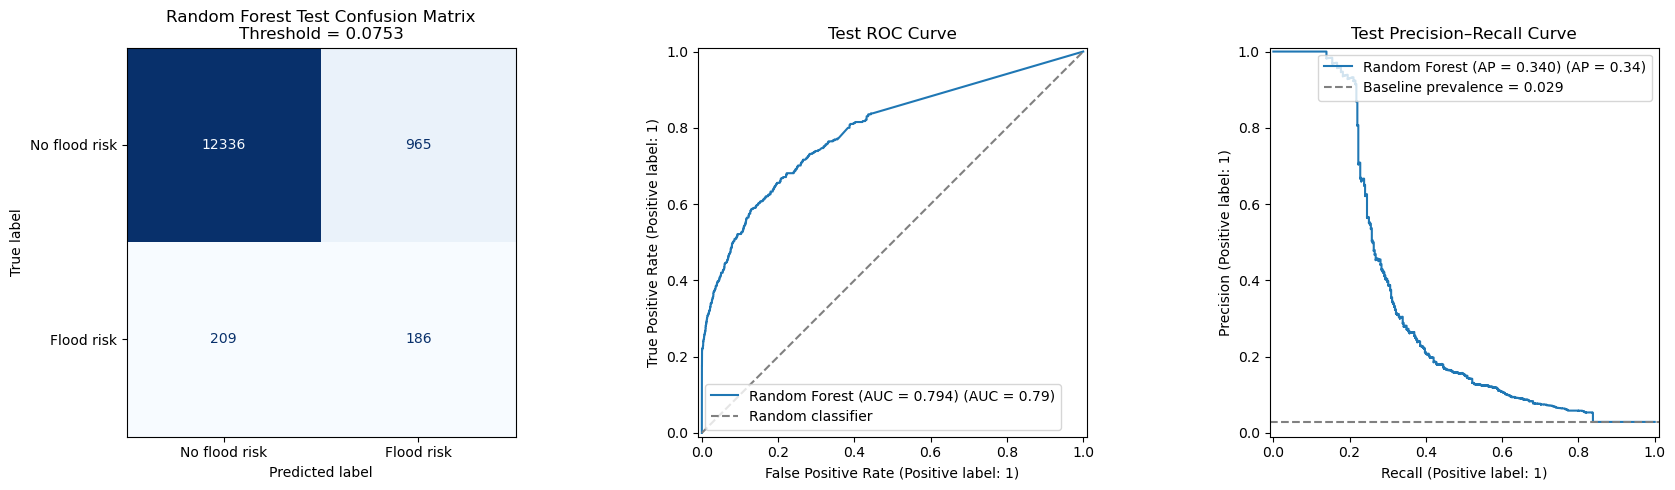

In [65]:
# Cell 67 - Random Forest test evaluation plots

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_predictions,
    display_labels=["No flood risk", "Flood risk"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title(
    "Random Forest Test Confusion Matrix\n"
    f"Threshold = {selected_rf_threshold:.4f}"
)

# ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    rf_test_probabilities,
    name=f"Random Forest (AUC = {roc_auc_score(y_test, rf_test_probabilities):.3f})",
    ax=axes[1]
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

axes[1].set_title("Test ROC Curve")
axes[1].legend()

# Precision-recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    rf_test_probabilities,
    name=(
        "Random Forest "
        f"(AP = {average_precision_score(y_test, rf_test_probabilities):.3f})"
    ),
    ax=axes[2]
)

test_prevalence = y_test.mean()

axes[2].axhline(
    test_prevalence,
    linestyle="--",
    color="grey",
    label=f"Baseline prevalence = {test_prevalence:.3f}"
)

axes[2].set_title("Test Precision–Recall Curve")
axes[2].legend()

plt.tight_layout()
plt.show()

,feature,importance
0,discharge_m3s,0.083
1,discharge_lag_1h,0.066
2,water_level_m,0.057
3,rainfall_sum_48h,0.046
4,water_level_lag_1h,0.045
5,discharge_lag_2h,0.043
6,discharge_lag_24h,0.041
7,water_level_lag_24h,0.041
8,water_level_lag_2h,0.041
9,discharge_lag_3h,0.035


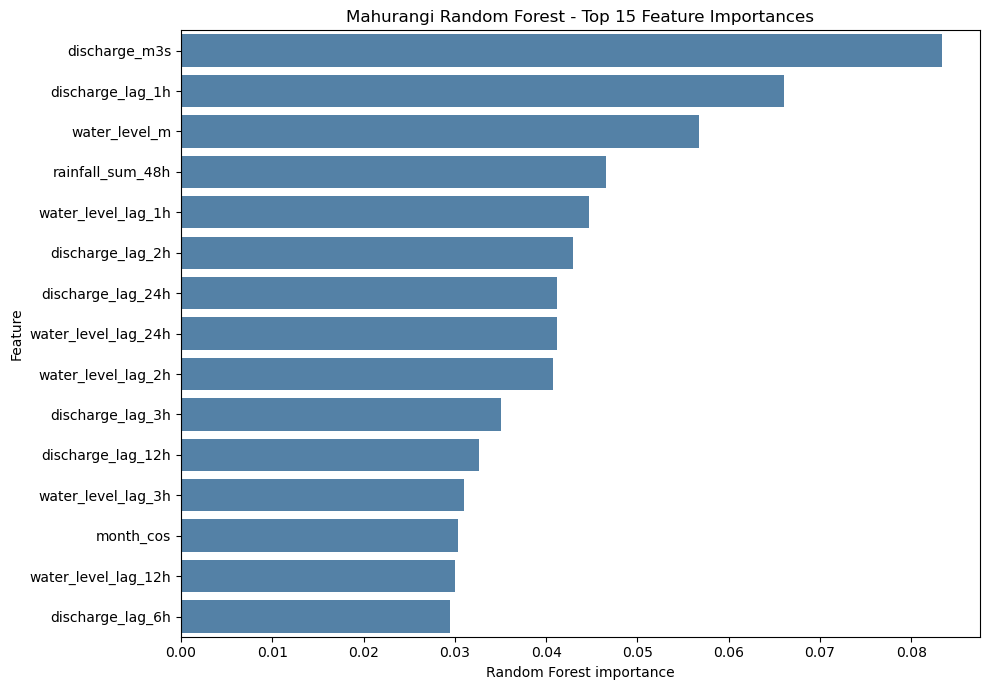

In [66]:
# Cell 68 - Random Forest feature importance

feature_importance_rf = (
    pd.DataFrame({
        "feature": X_train.columns,
        "importance": random_forest_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance_rf.head(15).round(4))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_rf.head(15),
    x="importance",
    y="feature",
    color="steelblue"
)

plt.title("Mahurangi Random Forest - Top 15 Feature Importances")
plt.xlabel("Random Forest importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 9. Event-Level Diagnostic Evaluation
The following analysis groups consecutive model-defined high-water-risk hours into episodes and checks whether each episode contains at least one positive model prediction. These episodes are derived from the statistical target and are not independently verified historical flood events.
Therefore, event-level recall indicates detection of model-defined high-water-risk episodes, not detection of all officially recorded floods. Alert episodes are also considered associated with risk when at least one predicted-positive hour overlaps a model-defined risk period.

In [67]:
# Cell 69 - Event-level evaluation of test flood-risk periods

event_evaluation = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]).to_numpy(),
    "actual": np.asarray(y_test).astype(int),
    "predicted": rf_test_predictions,
    "risk_score": rf_test_probabilities
})

# Identify whether each row follows the previous row by exactly one hour
event_evaluation["hourly_continuity"] = (
    event_evaluation["timestamp"].diff() == pd.Timedelta(hours=1)
)

# Start a new event when the target changes from 0 to 1
# or when consecutive positive rows are separated by a timestamp gap
event_evaluation["event_start"] = (
    (event_evaluation["actual"] == 1)
    & (
        (event_evaluation["actual"].shift(fill_value=0) == 0)
        | (~event_evaluation["hourly_continuity"])
    )
)

event_evaluation["event_id"] = (
    event_evaluation["event_start"].cumsum()
)

# Keep only actual flood-risk hours
actual_event_hours = event_evaluation[
    event_evaluation["actual"] == 1
].copy()

event_summary = (
    actual_event_hours
    .groupby("event_id")
    .agg(
        event_duration_hours=("actual", "size"),
        detected_hours=("predicted", "sum"),
        maximum_risk_score=("risk_score", "max"),
        mean_risk_score=("risk_score", "mean")
    )
)

event_summary["event_detected"] = (
    event_summary["detected_hours"] > 0
)

event_summary["hourly_detection_percentage"] = (
    100
    * event_summary["detected_hours"]
    / event_summary["event_duration_hours"]
)

total_events = len(event_summary)
detected_events = int(event_summary["event_detected"].sum())
missed_events = total_events - detected_events
event_recall = detected_events / total_events if total_events else np.nan

print("EVENT-LEVEL TEST RESULTS")
print(f"Total flood-risk episodes: {total_events}")
print(f"Detected episodes: {detected_events}")
print(f"Completely missed episodes: {missed_events}")
print(f"Event-level recall: {event_recall:.3f}")

display(
    event_summary
    .sort_values(
        ["event_detected", "event_duration_hours"],
        ascending=[True, False]
    )
    .round(3)
)

EVENT-LEVEL TEST RESULTS
Total flood-risk episodes: 16
Detected episodes: 15
Completely missed episodes: 1
Event-level recall: 0.938


,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
event_id,,,,,,
2,2,0,0.013,0.008,False,0.000
15,45,26,1.000,0.475,True,57.778
14,40,13,0.949,0.190,True,32.500
13,35,26,1.000,0.355,True,74.286
10,31,9,0.993,0.232,True,29.032
12,31,19,0.990,0.278,True,61.290
11,30,24,1.000,0.360,True,80.000
6,29,12,0.997,0.226,True,41.379
7,29,12,0.910,0.219,True,41.379


In [68]:
# Cell 70 - Evaluate alert episodes and false-alarm burden

alert_evaluation = event_evaluation.copy()

# Start a new alert episode whenever prediction changes from 0 to 1
alert_evaluation["alert_start"] = (
    (alert_evaluation["predicted"] == 1)
    & (
        (alert_evaluation["predicted"].shift(fill_value=0) == 0)
        | (~alert_evaluation["hourly_continuity"])
    )
)

alert_evaluation["alert_id"] = (
    alert_evaluation["alert_start"].cumsum()
)

predicted_alert_hours = alert_evaluation[
    alert_evaluation["predicted"] == 1
].copy()

alert_summary = (
    predicted_alert_hours
    .groupby("alert_id")
    .agg(
        alert_duration_hours=("predicted", "size"),
        actual_risk_hours=("actual", "sum"),
        maximum_risk_score=("risk_score", "max"),
        mean_risk_score=("risk_score", "mean")
    )
)

# An alert episode is associated with risk if at least one hour
# overlaps an actual model-defined risk window
alert_summary["associated_with_risk"] = (
    alert_summary["actual_risk_hours"] > 0
)

total_alert_episodes = len(alert_summary)

associated_alert_episodes = int(
    alert_summary["associated_with_risk"].sum()
)

false_alert_episodes = (
    total_alert_episodes - associated_alert_episodes
)

alert_episode_precision = (
    associated_alert_episodes / total_alert_episodes
    if total_alert_episodes > 0
    else np.nan
)

print("ALERT-EPISODE TEST RESULTS")
print(f"Total alert episodes: {total_alert_episodes}")
print(
    "Alert episodes overlapping a risk period:",
    associated_alert_episodes
)
print(
    "Alert episodes with no risk-period overlap:",
    false_alert_episodes
)
print(
    f"Alert-episode precision: {alert_episode_precision:.3f}"
)

print("\nAlert duration summary:")
display(
    alert_summary[
        ["alert_duration_hours", "associated_with_risk"]
    ]
    .groupby("associated_with_risk")
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

print("\nLongest false-alert episodes:")
display(
    alert_summary[
        ~alert_summary["associated_with_risk"]
    ]
    .sort_values(
        "alert_duration_hours",
        ascending=False
    )
    .head(15)
    .round(3)
)

ALERT-EPISODE TEST RESULTS
Total alert episodes: 274
Alert episodes overlapping a risk period: 27
Alert episodes with no risk-period overlap: 247
Alert-episode precision: 0.099

Alert duration summary:


alert_duration_hours                 
                                    count  mean median max
associated_with_risk                                      
False                                 247 3.630  2.000  25
True                                   27 9.410  9.000  28


Longest false-alert episodes:


,alert_duration_hours,actual_risk_hours,maximum_risk_score,mean_risk_score,associated_with_risk
alert_id,,,,,
39,25,0,0.509,0.202,False
49,23,0,0.556,0.216,False
200,20,0,0.666,0.343,False
144,19,0,0.329,0.181,False
143,19,0,0.818,0.294,False
178,19,0,0.692,0.272,False
203,16,0,0.497,0.280,False
193,14,0,0.406,0.186,False
141,14,0,0.618,0.323,False


## 10. Data Export

In [69]:
# Cell 71 - Export the final Mahurangi datasets

from pathlib import Path

output_directory = Path("outputs/mahurangi")
output_directory.mkdir(parents=True, exist_ok=True)

cleaned_data_path = (
    output_directory
    / "mahurangi_cleaned_hourly.csv"
)

classifier_data_path = (
    output_directory
    / "mahurangi_classifier_ready.csv"
)

mahurangi_base.to_csv(
    cleaned_data_path,
    index=False
)

modelling_dataset.to_csv(
    classifier_data_path,
    index=False
)

print("Saved cleaned hourly dataset:")
print(cleaned_data_path)
print("Shape:", mahurangi_base.shape)

print("\nSaved classifier-ready dataset:")
print(classifier_data_path)
print("Shape:", modelling_dataset.shape)

Saved cleaned hourly dataset:
outputs\mahurangi\mahurangi_cleaned_hourly.csv
Shape: (96432, 10)

Saved classifier-ready dataset:
outputs\mahurangi\mahurangi_classifier_ready.csv
Shape: (94991, 39)


## Gaussian Naive Bayes Classification

In [70]:
# Import libraries 
# Mahurangi - Gaussian Naive Bayse classification

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option(
    "display.float_format",
    lambda value: f"{value:,.4f}"
)

sns.set_theme(style="whitegrid")

In [71]:
# Load the Mahurangi classifier-ready dataset

mahurangi_data = pd.read_csv(
    r"C:\Users\kgeet\Downloads\mahurangi_classifier_ready.csv",
    parse_dates=["timestamp"]
)

mahurangi_data = (
    mahurangi_data
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("Mahurangi dataset loaded successfully.")
print("Dataset shape:", mahurangi_data.shape)

print(
    "Study period:",
    mahurangi_data["timestamp"].min(),
    "to",
    mahurangi_data["timestamp"].max()
)

display(mahurangi_data.head())

Mahurangi dataset loaded successfully.
Dataset shape: (94991, 39)
Study period: 2015-01-03 00:00:00 to 2025-12-31 00:00:00


,rainfall_mm,discharge_m3s,water_level_m,rainfall_lag_1h,rainfall_lag_2h,rainfall_lag_3h,rainfall_lag_6h,rainfall_lag_12h,rainfall_lag_24h,rainfall_sum_3h,rainfall_sum_6h,rainfall_sum_12h,rainfall_sum_24h,rainfall_sum_48h,discharge_lag_1h,discharge_lag_2h,discharge_lag_3h,discharge_lag_6h,discharge_lag_12h,discharge_lag_24h,water_level_lag_1h,water_level_lag_2h,water_level_lag_3h,water_level_lag_6h,water_level_lag_12h,water_level_lag_24h,discharge_change_1h,discharge_change_3h,discharge_change_6h,water_level_change_1h,water_level_change_3h,water_level_change_6h,hour_sin,hour_cos,month_sin,month_cos,flood_next_24h,timestamp,data_period
0,0.0000,0.2710,1.3220,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.4900,0.2800,0.2800,0.2800,0.2910,0.2910,0.3070,1.3240,1.3240,1.3240,1.3260,1.3260,1.3290,-0.0090,-0.0090,-0.0200,-0.0020,-0.0020,-0.0040,0.0000,1.0000,0.0000,1.0000,0,2015-01-03 00:00:00,train
1,0.0000,0.2710,1.3220,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.4900,0.2710,0.2800,0.2800,0.2860,0.2910,0.3010,1.3220,1.3240,1.3240,1.3250,1.3260,1.3280,0.0000,-0.0090,-0.0150,0.0000,-0.0020,-0.0030,0.2588,0.9659,0.0000,1.0000,0,2015-01-03 01:00:00,train
2,0.0000,0.2660,1.3210,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.4900,0.2710,0.2710,0.2800,0.2860,0.2910,0.2960,1.3220,1.3220,1.3240,1.3250,1.3260,1.3270,-0.0050,-0.0140,-0.0200,-0.0010,-0.0030,-0.0040,0.5000,0.8660,0.0000,1.0000,0,2015-01-03 02:00:00,train
3,0.0000,0.2660,1.3210,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.2400,0.2660,0.2710,0.2710,0.2800,0.2910,0.2910,1.3210,1.3220,1.3220,1.3240,1.3260,1.3260,0.0000,-0.0050,-0.0140,0.0000,-0.0010,-0.0030,0.7071,0.7071,0.0000,1.0000,0,2015-01-03 03:00:00,train
4,0.0000,0.2610,1.3200,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2660,0.2660,0.2710,0.2800,0.2910,0.2860,1.3210,1.3210,1.3220,1.3240,1.3260,1.3250,-0.0050,-0.0100,-0.0190,-0.0010,-0.0020,-0.0040,0.8660,0.5000,0.0000,1.0000,0,2015-01-03 04:00:00,train


In [72]:
# Validate the loaded dataset

print(
    "Duplicate timestamps:",
    mahurangi_data["timestamp"].duplicated().sum()
)

print(
    "Duplicate rows:",
    mahurangi_data.duplicated().sum()
)

print(
    "Total missing values:",
    mahurangi_data.isna().sum().sum()
)

numeric_data = mahurangi_data.select_dtypes(
    include=np.number
)

print(
    "Total infinite numeric values:",
    np.isinf(numeric_data.to_numpy()).sum()
)

print("\nColumn data types:")
print(mahurangi_data.dtypes)

Duplicate timestamps: 0
Duplicate rows: 0
Total missing values: 0
Total infinite numeric values: 0

Column data types:
rainfall_mm                     float64
discharge_m3s                   float64
water_level_m                   float64
rainfall_lag_1h                 float64
rainfall_lag_2h                 float64
rainfall_lag_3h                 float64
rainfall_lag_6h                 float64
rainfall_lag_12h                float64
rainfall_lag_24h                float64
rainfall_sum_3h                 float64
rainfall_sum_6h                 float64
rainfall_sum_12h                float64
rainfall_sum_24h                float64
rainfall_sum_48h                float64
discharge_lag_1h                float64
discharge_lag_2h                float64
discharge_lag_3h                float64
discharge_lag_6h                float64
discharge_lag_12h               float64
discharge_lag_24h               float64
water_level_lag_1h              float64
water_level_lag_2h              float64
w

In [73]:
# Define target, split and predictor columns

timestamp_column = "timestamp"
split_column = "data_period"
target_column = "flood_next_24h"

excluded_columns = [
    timestamp_column,
    split_column,
    target_column
]

feature_columns = [
    column
    for column in mahurangi_data.columns
    if column not in excluded_columns
]

# Ensure target is binary
mahurangi_data[target_column] = (
    mahurangi_data[target_column]
    .astype("int8")
)

# Confirm all model features are numeric
non_numeric_features = (
    mahurangi_data[feature_columns]
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

if non_numeric_features:
    raise TypeError(
        "Non-numeric predictor columns found: "
        f"{non_numeric_features}"
    )

target_values = sorted(
    mahurangi_data[target_column].unique()
)

if target_values != [0, 1]:
    raise ValueError(
        "The target must contain only 0 and 1. "
        f"Found: {target_values}"
    )

print("Timestamp column:", timestamp_column)
print("Split column:", split_column)
print("Target column:", target_column)
print("Number of model features:", len(feature_columns))

print("\nModel features:")

for feature_number, feature_name in enumerate(
    feature_columns,
    start=1
):
    print(f"{feature_number:>2}. {feature_name}")

Timestamp column: timestamp
Split column: data_period
Target column: flood_next_24h
Number of model features: 36

Model features:
 1. rainfall_mm
 2. discharge_m3s
 3. water_level_m
 4. rainfall_lag_1h
 5. rainfall_lag_2h
 6. rainfall_lag_3h
 7. rainfall_lag_6h
 8. rainfall_lag_12h
 9. rainfall_lag_24h
10. rainfall_sum_3h
11. rainfall_sum_6h
12. rainfall_sum_12h
13. rainfall_sum_24h
14. rainfall_sum_48h
15. discharge_lag_1h
16. discharge_lag_2h
17. discharge_lag_3h
18. discharge_lag_6h
19. discharge_lag_12h
20. discharge_lag_24h
21. water_level_lag_1h
22. water_level_lag_2h
23. water_level_lag_3h
24. water_level_lag_6h
25. water_level_lag_12h
26. water_level_lag_24h
27. discharge_change_1h
28. discharge_change_3h
29. discharge_change_6h
30. water_level_change_1h
31. water_level_change_3h
32. water_level_change_6h
33. hour_sin
34. hour_cos
35. month_sin
36. month_cos


In [74]:
# Audit chronological partitions and target distribution

expected_split_labels = {
    "train",
    "validation",
    "test"
}

actual_split_labels = set(
    mahurangi_data[split_column].unique()
)

if actual_split_labels != expected_split_labels:
    raise ValueError(
        "Unexpected data-period labels. "
        f"Found: {sorted(actual_split_labels)}"
    )

split_summary = (
    mahurangi_data
    .groupby(split_column, sort=False)
    .agg(
        rows=(target_column, "size"),
        high_risk_rows=(target_column, "sum"),
        beginning=(timestamp_column, "min"),
        ending=(timestamp_column, "max")
    )
)

split_summary["normal_rows"] = (
    split_summary["rows"]
    - split_summary["high_risk_rows"]
)

split_summary["high_risk_percentage"] = (
    100
    * split_summary["high_risk_rows"]
    / split_summary["rows"]
)

split_summary = split_summary[
    [
        "rows",
        "normal_rows",
        "high_risk_rows",
        "high_risk_percentage",
        "beginning",
        "ending"
    ]
]

print("Mahurangi chronological split summary:")

display(
    split_summary.round(4)
)

Mahurangi chronological split summary:


,rows,normal_rows,high_risk_rows,high_risk_percentage,beginning,ending
data_period,,,,,,
train,67153,65854,1299,1.9344,2015-01-03 00:00:00,2022-09-12 14:00:00
validation,14142,13362,780,5.5155,2022-09-13 15:00:00,2024-05-07 07:00:00
test,13696,13301,395,2.8841,2024-05-08 08:00:00,2025-12-31 00:00:00


In [75]:
# Create chronological model datasets

training_data = mahurangi_data.loc[
    mahurangi_data[split_column].eq("train")
].copy()

validation_data = mahurangi_data.loc[
    mahurangi_data[split_column].eq("validation")
].copy()

test_data = mahurangi_data.loc[
    mahurangi_data[split_column].eq("test")
].copy()

X_train = training_data[feature_columns].copy()
y_train = training_data[target_column].copy()

X_validation = validation_data[
    feature_columns
].copy()

y_validation = validation_data[
    target_column
].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data[target_column].copy()

training_timestamps = training_data[
    timestamp_column
].copy()

validation_timestamps = validation_data[
    timestamp_column
].copy()

test_timestamps = test_data[
    timestamp_column
].copy()

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_validation.shape)
print("Test matrix:", X_test.shape)

print("\nTraining high-risk rows:", int(y_train.sum()))

print(
    "Validation high-risk rows:",
    int(y_validation.sum())
)

print("Test high-risk rows:", int(y_test.sum()))

Training matrix: (67153, 36)
Validation matrix: (14142, 36)
Test matrix: (13696, 36)

Training high-risk rows: 1299
Validation high-risk rows: 780
Test high-risk rows: 395


In [76]:
# Tune var_smoothing and probability threshold using validation F2

var_smoothing_values = np.logspace(
    -12,
    3,
    31
)

tuning_results = []

for var_smoothing in var_smoothing_values:

    candidate_model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "naive_bayes",
            GaussianNB(
                var_smoothing=var_smoothing
            )
        )
    ])

    candidate_model.fit(
        X_train,
        y_train
    )

    candidate_probability = (
        candidate_model.predict_proba(
            X_validation
        )[:, 1]
    )

    candidate_precision, candidate_recall, candidate_thresholds = (
        precision_recall_curve(
            y_validation,
            candidate_probability
        )
    )

    candidate_precision = candidate_precision[:-1]
    candidate_recall = candidate_recall[:-1]

    candidate_f2 = (
        5
        * candidate_precision
        * candidate_recall
        / (
            4 * candidate_precision
            + candidate_recall
            + 1e-15
        )
    )

    best_position = int(
        np.argmax(candidate_f2)
    )

    tuning_results.append({
        "var_smoothing": var_smoothing,

        "selected_threshold":
            candidate_thresholds[best_position],

        "validation_precision":
            candidate_precision[best_position],

        "validation_recall":
            candidate_recall[best_position],

        "validation_f2":
            candidate_f2[best_position],

        "validation_roc_auc":
            roc_auc_score(
                y_validation,
                candidate_probability
            ),

        "validation_pr_auc":
            average_precision_score(
                y_validation,
                candidate_probability
            )
    })

naive_bayes_tuning_results = pd.DataFrame(
    tuning_results
)

# Several small smoothing values produce exactly the same maximum F2. 
# Use the standard GaussianNB default of 1e-9 when it belongs to the best-performing plateau.

maximum_validation_f2 = (
    naive_bayes_tuning_results[
        "validation_f2"
    ].max()
)

best_f2_candidates = (
    naive_bayes_tuning_results.loc[
        np.isclose(
            naive_bayes_tuning_results[
                "validation_f2"
            ],
            maximum_validation_f2,
            rtol=0,
            atol=1e-10
        )
    ]
    .copy()
)

default_smoothing = 1e-9

if np.isclose(
    best_f2_candidates["var_smoothing"],
    default_smoothing,
    rtol=1e-8,
    atol=0
).any():

    selected_tuning_row = (
        best_f2_candidates.iloc[
            np.argmin(
                np.abs(
                    np.log10(
                        best_f2_candidates[
                            "var_smoothing"
                        ]
                    )
                    - np.log10(
                        default_smoothing
                    )
                )
            )
        ]
    )

else:
    selected_tuning_row = (
        naive_bayes_tuning_results
        .sort_values(
            [
                "validation_f2",
                "validation_pr_auc"
            ],
            ascending=False
        )
        .iloc[0]
    )

best_var_smoothing = float(
    selected_tuning_row["var_smoothing"]
)

selected_probability_threshold = float(
    selected_tuning_row[
        "selected_threshold"
    ]
)

print(
    "Selected var_smoothing:",
    f"{best_var_smoothing:.3e}"
)

print(
    "Selected probability threshold:",
    f"{selected_probability_threshold:.6e}"
)

print(
    "Maximum validation F2:",
    f"{selected_tuning_row['validation_f2']:.4f}"
)

print("\nTop validation results:")

display(
    naive_bayes_tuning_results
    .sort_values(
        [
            "validation_f2",
            "validation_pr_auc"
        ],
        ascending=False
    )
    .head(10)
    .style.format({
        "var_smoothing": "{:.3e}",
        "selected_threshold": "{:.6e}",
        "validation_precision": "{:.4f}",
        "validation_recall": "{:.4f}",
        "validation_f2": "{:.4f}",
        "validation_roc_auc": "{:.4f}",
        "validation_pr_auc": "{:.4f}"
    })
)

Selected var_smoothing: 1.000e-09
Selected probability threshold: 9.778689e-13
Maximum validation F2: 0.4406

Top validation results:


,var_smoothing,selected_threshold,validation_precision,validation_recall,validation_f2,validation_roc_auc,validation_pr_auc
19,3.162e-03,9.211092e-13,0.2349,0.5641,0.4406,0.8151,0.2349
17,3.162e-04,9.719816e-13,0.2349,0.5641,0.4406,0.8150,0.2346
18,1.000e-03,9.594158e-13,0.2349,0.5641,0.4406,0.8150,0.2346
13,3.162e-06,9.778098e-13,0.2349,0.5641,0.4406,0.8150,0.2345
14,1.000e-05,9.776820e-13,0.2349,0.5641,0.4406,0.8150,0.2345
12,1.000e-06,9.778502e-13,0.2349,0.5641,0.4406,0.8150,0.2345
0,1.000e-12,9.778689e-13,0.2349,0.5641,0.4406,0.8150,0.2345
1,3.162e-12,9.778689e-13,0.2349,0.5641,0.4406,0.8150,0.2345
2,1.000e-11,9.778689e-13,0.2349,0.5641,0.4406,0.8150,0.2345
3,3.162e-11,9.778689e-13,0.2349,0.5641,0.4406,0.8150,0.2345


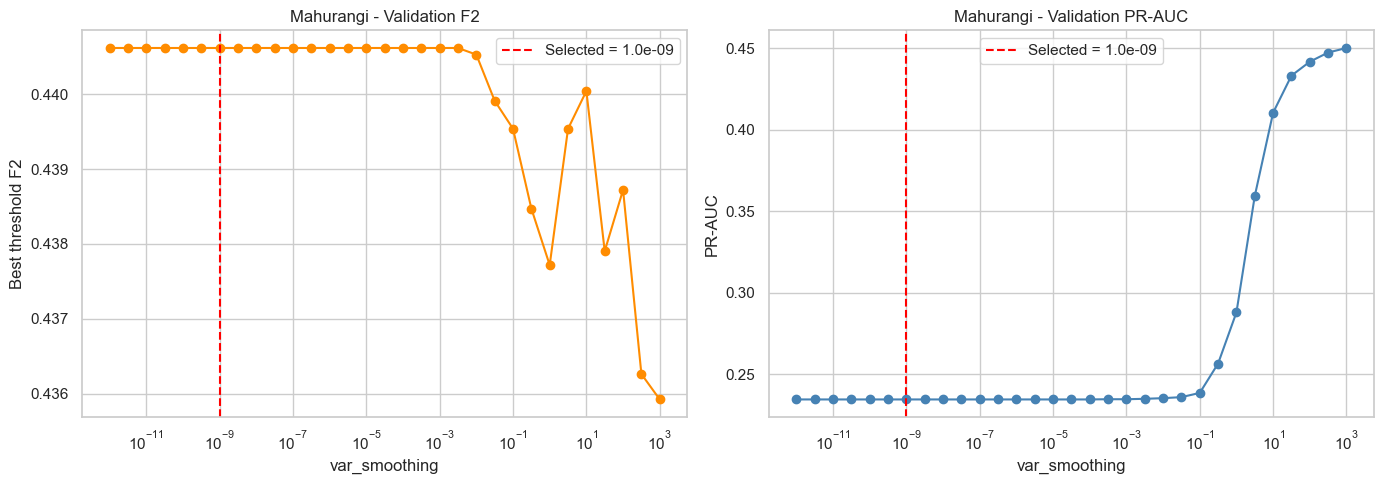

In [77]:
# Plot validation tuning results

sorted_tuning_results = (
    naive_bayes_tuning_results
    .sort_values("var_smoothing")
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].semilogx(
    sorted_tuning_results[
        "var_smoothing"
    ],
    sorted_tuning_results[
        "validation_f2"
    ],
    marker="o",
    color="darkorange"
)

axes[0].axvline(
    best_var_smoothing,
    color="red",
    linestyle="--",
    label=(
        "Selected = "
        f"{best_var_smoothing:.1e}"
    )
)

axes[0].set_title(
    "Mahurangi - Validation F2"
)

axes[0].set_xlabel("var_smoothing")
axes[0].set_ylabel("Best threshold F2")
axes[0].legend()

axes[1].semilogx(
    sorted_tuning_results[
        "var_smoothing"
    ],
    sorted_tuning_results[
        "validation_pr_auc"
    ],
    marker="o",
    color="steelblue"
)

axes[1].axvline(
    best_var_smoothing,
    color="red",
    linestyle="--",
    label=(
        "Selected = "
        f"{best_var_smoothing:.1e}"
    )
)

axes[1].set_title(
    "Mahurangi - Validation PR-AUC"
)

axes[1].set_xlabel("var_smoothing")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [78]:
# Fit the selected Gaussian Naive Bayes model

naive_bayes_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "naive_bayes",
        GaussianNB(
            var_smoothing=best_var_smoothing
        )
    )
])

naive_bayes_model.fit(
    X_train,
    y_train
)

training_probability = (
    naive_bayes_model.predict_proba(
        X_train
    )[:, 1]
)

validation_probability = (
    naive_bayes_model.predict_proba(
        X_validation
    )[:, 1]
)

print("Gaussian Naive Bayes fitted successfully.")

print(
    "Selected var_smoothing:",
    f"{best_var_smoothing:.3e}"
)

print(
    "Frozen validation-selected threshold:",
    f"{selected_probability_threshold:.6e}"
)

print(
    "Training probabilities:",
    len(training_probability)
)

print(
    "Validation probabilities:",
    len(validation_probability)
)

Gaussian Naive Bayes fitted successfully.
Selected var_smoothing: 1.000e-09
Frozen validation-selected threshold: 9.778689e-13
Training probabilities: 67153
Validation probabilities: 14142


In [79]:
# Evaluate the validation partition using the frozen selected threshold

validation_prediction = (
    validation_probability
    >= selected_probability_threshold
).astype(int)

validation_confusion_matrix = confusion_matrix(
    y_validation,
    validation_prediction
)

tn, fp, fn, tp = (
    validation_confusion_matrix.ravel()
)

validation_results = pd.DataFrame({
    "value": {
        "var_smoothing":
            best_var_smoothing,

        "selected_threshold":
            selected_probability_threshold,

        "accuracy":
            accuracy_score(
                y_validation,
                validation_prediction
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_validation,
                validation_prediction
            ),

        "precision":
            precision_score(
                y_validation,
                validation_prediction,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_validation,
                validation_prediction,
                zero_division=0
            ),

        "f1_score":
            f1_score(
                y_validation,
                validation_prediction,
                zero_division=0
            ),

        "f2_score":
            fbeta_score(
                y_validation,
                validation_prediction,
                beta=2,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_validation,
                validation_probability
            ),

        "pr_auc":
            average_precision_score(
                y_validation,
                validation_probability
            ),

        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    }
})

print(
    "GAUSSIAN NAIVE BAYES - TUNED VALIDATION RESULTS"
)

display(
    validation_results.style.format({
        "value": "{:.6g}"
    })
)

print("\nValidation confusion matrix:")

display(
    pd.DataFrame(
        validation_confusion_matrix,
        index=[
            "Actual normal",
            "Actual high risk"
        ],
        columns=[
            "Predicted normal",
            "Predicted high risk"
        ]
    )
)

print("\nValidation classification report:")

print(
    classification_report(
        y_validation,
        validation_prediction,
        target_names=[
            "Normal",
            "High risk"
        ],
        digits=4,
        zero_division=0
    )
)

GAUSSIAN NAIVE BAYES - TUNED VALIDATION RESULTS


,value
var_smoothing,1e-09
selected_threshold,9.77869e-13
accuracy,0.874629
balanced_accuracy,0.728429
precision,0.234917
recall,0.564103
f1_score,0.3317
f2_score,0.440617
roc_auc,0.814992
pr_auc,0.234479



Validation confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,11929,1433
Actual high risk,340,440



Validation classification report:
              precision    recall  f1-score   support

      Normal     0.9723    0.8928    0.9308     13362
   High risk     0.2349    0.5641    0.3317       780

    accuracy                         0.8746     14142
   macro avg     0.6036    0.7284    0.6313     14142
weighted avg     0.9316    0.8746    0.8978     14142



In [80]:
# Select the probability threshold using validation F2

threshold_precision, threshold_recall, thresholds = (
    precision_recall_curve(
        y_validation,
        validation_probability
    )
)

# The final precision and recall values do not have
# a corresponding threshold
threshold_precision = threshold_precision[:-1]
threshold_recall = threshold_recall[:-1]

threshold_f1 = (
    2
    * threshold_precision
    * threshold_recall
    / (
        threshold_precision
        + threshold_recall
        + 1e-15
    )
)

threshold_f2 = (
    5
    * threshold_precision
    * threshold_recall
    / (
        4 * threshold_precision
        + threshold_recall
        + 1e-15
    )
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": threshold_precision,
    "recall": threshold_recall,
    "f1_score": threshold_f1,
    "f2_score": threshold_f2
})

best_threshold_position = (
    threshold_results["f2_score"].idxmax()
)

selected_probability_threshold = float(
    threshold_results.loc[
        best_threshold_position,
        "threshold"
    ]
)

selected_threshold_result = (
    threshold_results.loc[
        [best_threshold_position]
    ]
    .reset_index(drop=True)
)

print(
    "Selected validation probability threshold:",
    f"{selected_probability_threshold:.6f}"
)

print("\nBest validation F2 result:")

display(
    selected_threshold_result.round(4)
)

Selected validation probability threshold: 0.000000

Best validation F2 result:


,threshold,precision,recall,f1_score,f2_score
0,0.0000,0.2349,0.5641,0.3317,0.4406


In [82]:
# Evaluate the frozen model on the untouched test set

test_probability = (
    naive_bayes_model.predict_proba(
        X_test
    )[:, 1]
)

test_prediction = (
    test_probability
    >= selected_probability_threshold
).astype(int)

test_confusion_matrix = confusion_matrix(
    y_test,
    test_prediction
)

tn, fp, fn, tp = test_confusion_matrix.ravel()

naive_bayes_test_results = pd.DataFrame({
    "model": ["Gaussian Naive Bayes"],
    "var_smoothing": [best_var_smoothing],
    "selected_threshold": [
        selected_probability_threshold
    ],
    "rows": [len(y_test)],
    "actual_high_risk": [int(y_test.sum())],
    "predicted_high_risk": [
        int(test_prediction.sum())
    ],
    "accuracy": [
        accuracy_score(
            y_test,
            test_prediction
        )
    ],
    "balanced_accuracy": [
        balanced_accuracy_score(
            y_test,
            test_prediction
        )
    ],
    "precision": [
        precision_score(
            y_test,
            test_prediction,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_test,
            test_prediction,
            zero_division=0
        )
    ],
    "f1_score": [
        f1_score(
            y_test,
            test_prediction,
            zero_division=0
        )
    ],
    "f2_score": [
        fbeta_score(
            y_test,
            test_prediction,
            beta=2,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(
            y_test,
            test_probability
        )
    ],
    "pr_auc": [
        average_precision_score(
            y_test,
            test_probability
        )
    ],
    "true_negatives": [tn],
    "false_positives": [fp],
    "false_negatives": [fn],
    "true_positives": [tp]
})

print(
    "MAHURANGI GAUSSIAN NAIVE BAYES - FINAL UNTOUCHED-TEST RESULTS"
)

display(
    naive_bayes_test_results.style.format({
        "var_smoothing": "{:.3e}",
        "selected_threshold": "{:.6e}",
        "accuracy": "{:.4f}",
        "balanced_accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1_score": "{:.4f}",
        "f2_score": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

print("\nFinal test confusion matrix:")

display(
    pd.DataFrame(
        test_confusion_matrix,
        index=[
            "Actual normal",
            "Actual high risk"
        ],
        columns=[
            "Predicted normal",
            "Predicted high risk"
        ]
    )
)

print("\nFinal test classification report:")

print(
    classification_report(
        y_test,
        test_prediction,
        target_names=[
            "Normal",
            "High risk"
        ],
        digits=4,
        zero_division=0
    )
)

MAHURANGI GAUSSIAN NAIVE BAYES - FINAL UNTOUCHED-TEST RESULTS


,model,var_smoothing,selected_threshold,rows,actual_high_risk,predicted_high_risk,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_negatives,false_positives,false_negatives,true_positives
0,Gaussian Naive Bayes,1.000e-09,9.778689e-13,13696,395,1337,0.9019,0.7026,0.1451,0.4911,0.2240,0.3325,0.7922,0.1397,12158,1143,201,194



Final test confusion matrix:


,Predicted normal,Predicted high risk
Actual normal,12158,1143
Actual high risk,201,194



Final test classification report:
              precision    recall  f1-score   support

      Normal     0.9837    0.9141    0.9476     13301
   High risk     0.1451    0.4911    0.2240       395

    accuracy                         0.9019     13696
   macro avg     0.5644    0.7026    0.5858     13696
weighted avg     0.9595    0.9019    0.9268     13696



In [83]:
# Create timestamp-level test diagnostics

mahurangi_naive_bayes_test_predictions = (
    pd.DataFrame({
        "timestamp":
            test_timestamps.to_numpy(),

        "observed_high_water_risk_24h":
            y_test.to_numpy(),

        "naive_bayes_score":
            test_probability,

        "predicted_high_water_risk_24h":
            test_prediction,

        "rainfall_mm":
            test_data["rainfall_mm"].to_numpy(),

        "discharge_m3s":
            test_data["discharge_m3s"].to_numpy(),

        "water_level_m":
            test_data["water_level_m"].to_numpy()
    })
)

print(
    "Test prediction rows:",
    len(
        mahurangi_naive_bayes_test_predictions
    )
)

print(
    "Missing prediction values:",
    mahurangi_naive_bayes_test_predictions
    .isna()
    .sum()
    .sum()
)

display(
    mahurangi_naive_bayes_test_predictions.head()
)

Test prediction rows: 13696
Missing prediction values: 0


,timestamp,observed_high_water_risk_24h,naive_bayes_score,predicted_high_water_risk_24h,rainfall_mm,discharge_m3s,water_level_m
0,2024-05-08 08:00:00,0,0.0000,0,0.0000,0.1420,1.2800
1,2024-05-08 09:00:00,0,0.0000,0,0.0000,0.1420,1.2800
2,2024-05-08 10:00:00,0,0.0000,0,0.0000,0.1420,1.2800
3,2024-05-08 11:00:00,0,0.0000,0,0.0000,0.1420,1.2800
4,2024-05-08 12:00:00,0,0.0000,0,0.0000,0.1400,1.2790


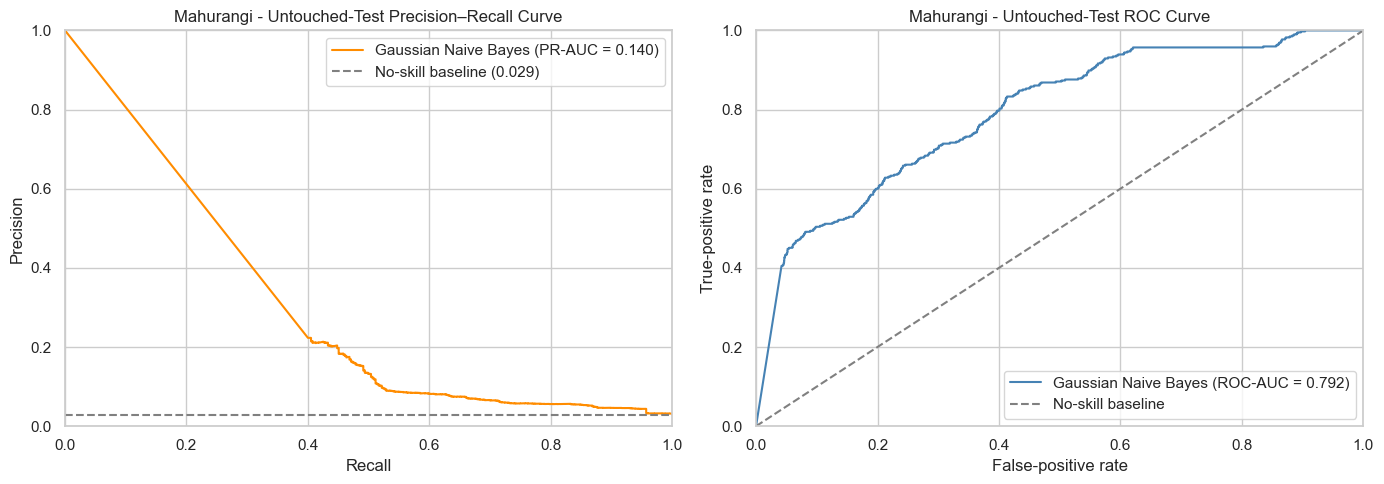

In [84]:
# Plot final test precision-recall and ROC curves

test_curve_precision, test_curve_recall, _ = (
    precision_recall_curve(
        y_test,
        test_probability
    )
)

test_false_positive_rate, test_true_positive_rate, _ = (
    roc_curve(
        y_test,
        test_probability
    )
)

test_pr_auc = average_precision_score(
    y_test,
    test_probability
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probability
)

test_positive_prevalence = y_test.mean()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    test_curve_recall,
    test_curve_precision,
    color="darkorange",
    label=(
        "Gaussian Naive Bayes "
        f"(PR-AUC = {test_pr_auc:.3f})"
    )
)

axes[0].axhline(
    test_positive_prevalence,
    color="gray",
    linestyle="--",
    label=(
        "No-skill baseline "
        f"({test_positive_prevalence:.3f})"
    )
)

axes[0].set_title(
    "Mahurangi - Untouched-Test Precision–Recall Curve"
)

axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(
    test_false_positive_rate,
    test_true_positive_rate,
    color="steelblue",
    label=(
        "Gaussian Naive Bayes "
        f"(ROC-AUC = {test_roc_auc:.3f})"
    )
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="No-skill baseline"
)

axes[1].set_title(
    "Mahurangi - Untouched-Test ROC Curve"
)

axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

In [85]:
# Cell 14 - Group consecutive observed high-risk hours into events

event_data = (
    mahurangi_naive_bayes_test_predictions
    .sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

timestamp_gap = (
    event_data["timestamp"]
    .diff()
    .ne(pd.Timedelta(hours=1))
)

previous_observed_risk = (
    event_data[
        "observed_high_water_risk_24h"
    ]
    .shift(fill_value=0)
)

new_observed_event = (
    event_data[
        "observed_high_water_risk_24h"
    ].eq(1)
    & (
        previous_observed_risk.ne(1)
        | timestamp_gap
    )
)

event_data["event_id"] = (
    new_observed_event.cumsum()
)

event_data.loc[
    event_data[
        "observed_high_water_risk_24h"
    ].eq(0),
    "event_id"
] = np.nan

observed_event_rows = event_data.loc[
    event_data["event_id"].notna()
].copy()

observed_event_rows["event_id"] = (
    observed_event_rows["event_id"].astype(int)
)

mahurangi_naive_bayes_event_results = (
    observed_event_rows
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),

        event_hours=(
            "observed_high_water_risk_24h",
            "size"
        ),

        detected_hours=(
            "predicted_high_water_risk_24h",
            "sum"
        ),

        maximum_naive_bayes_score=(
            "naive_bayes_score",
            "max"
        ),

        mean_naive_bayes_score=(
            "naive_bayes_score",
            "mean"
        ),

        maximum_water_level_m=(
            "water_level_m",
            "max"
        )
    )
    .reset_index()
)

mahurangi_naive_bayes_event_results[
    "event_detected"
] = (
    mahurangi_naive_bayes_event_results[
        "detected_hours"
    ].gt(0)
)

mahurangi_naive_bayes_event_results[
    "hourly_detection_percentage"
] = (
    100
    * mahurangi_naive_bayes_event_results[
        "detected_hours"
    ]
    / mahurangi_naive_bayes_event_results[
        "event_hours"
    ]
)

total_test_events = len(
    mahurangi_naive_bayes_event_results
)

detected_test_events = int(
    mahurangi_naive_bayes_event_results[
        "event_detected"
    ].sum()
)

test_event_recall = (
    detected_test_events
    / total_test_events
    if total_test_events > 0
    else np.nan
)

print("Physical high-risk events:", total_test_events)

print(
    "Events detected:",
    detected_test_events
)

print(
    "Event-level recall:",
    f"{test_event_recall:.3f}"
)

display(
    mahurangi_naive_bayes_event_results
)

Physical high-risk events: 16
Events detected: 14
Event-level recall: 0.875


,event_id,event_start,event_end,event_hours,detected_hours,maximum_naive_bayes_score,mean_naive_bayes_score,maximum_water_level_m,event_detected,hourly_detection_percentage
0,1,2024-05-20 00:00:00,2024-05-21 01:00:00,26,6,1.0000,0.2308,2.6620,True,23.0769
1,2,2024-06-13 15:00:00,2024-06-13 16:00:00,2,0,0.0000,0.0000,1.3580,False,0.0000
2,3,2024-06-13 18:00:00,2024-06-13 22:00:00,5,0,0.0000,0.0000,1.4080,False,0.0000
3,4,2024-06-14 00:00:00,2024-06-14 10:00:00,11,11,1.0000,0.9091,2.8390,True,100.0000
4,5,2024-06-14 12:00:00,2024-06-14 13:00:00,2,2,1.0000,1.0000,2.5090,True,100.0000
5,6,2024-06-15 22:00:00,2024-06-17 02:00:00,29,8,1.0000,0.2414,3.1710,True,27.5862
6,7,2024-07-14 16:00:00,2024-07-15 20:00:00,29,16,1.0000,0.4461,3.1530,True,55.1724
7,8,2024-07-19 02:00:00,2024-07-20 05:00:00,28,7,1.0000,0.2143,2.5210,True,25.0000
8,9,2024-08-29 01:00:00,2024-08-30 00:00:00,24,4,1.0000,0.1667,2.4210,True,16.6667
9,10,2025-04-18 00:00:00,2025-04-19 06:00:00,31,29,1.0000,0.7420,3.3880,True,93.5484


In [86]:
# Group consecutive predicted warnings into alert episodes

previous_predicted_risk = (
    event_data[
        "predicted_high_water_risk_24h"
    ]
    .shift(fill_value=0)
)

new_alert_episode = (
    event_data[
        "predicted_high_water_risk_24h"
    ].eq(1)
    & (
        previous_predicted_risk.ne(1)
        | timestamp_gap
    )
)

event_data["alert_id"] = (
    new_alert_episode.cumsum()
)

event_data.loc[
    event_data[
        "predicted_high_water_risk_24h"
    ].eq(0),
    "alert_id"
] = np.nan

alert_rows = event_data.loc[
    event_data["alert_id"].notna()
].copy()

alert_rows["alert_id"] = (
    alert_rows["alert_id"].astype(int)
)

mahurangi_naive_bayes_alert_results = (
    alert_rows
    .groupby("alert_id")
    .agg(
        alert_start=("timestamp", "min"),
        alert_end=("timestamp", "max"),

        alert_hours=(
            "predicted_high_water_risk_24h",
            "size"
        ),

        actual_risk_hours=(
            "observed_high_water_risk_24h",
            "sum"
        ),

        maximum_naive_bayes_score=(
            "naive_bayes_score",
            "max"
        ),

        mean_naive_bayes_score=(
            "naive_bayes_score",
            "mean"
        )
    )
    .reset_index()
)

mahurangi_naive_bayes_alert_results[
    "associated_with_risk"
] = (
    mahurangi_naive_bayes_alert_results[
        "actual_risk_hours"
    ].gt(0)
)

total_alert_episodes = len(
    mahurangi_naive_bayes_alert_results
)

useful_alert_episodes = int(
    mahurangi_naive_bayes_alert_results[
        "associated_with_risk"
    ].sum()
)

false_alert_episodes = (
    total_alert_episodes
    - useful_alert_episodes
)

alert_episode_precision = (
    useful_alert_episodes
    / total_alert_episodes
    if total_alert_episodes > 0
    else np.nan
)

print(
    "Total predicted alert episodes:",
    total_alert_episodes
)

print(
    "Risk-associated alert episodes:",
    useful_alert_episodes
)

print(
    "False alert episodes:",
    false_alert_episodes
)

print(
    "Alert-episode precision:",
    f"{alert_episode_precision:.3f}"
)

display(
    mahurangi_naive_bayes_alert_results.head(20)
)

Total predicted alert episodes: 116
Risk-associated alert episodes: 15
False alert episodes: 101
Alert-episode precision: 0.129


,alert_id,alert_start,alert_end,alert_hours,actual_risk_hours,maximum_naive_bayes_score,mean_naive_bayes_score,associated_with_risk
0,1,2024-05-15 06:00:00,2024-05-15 09:00:00,4,0,1.0000,0.7727,False
1,2,2024-05-15 12:00:00,2024-05-15 16:00:00,5,0,0.6758,0.1378,False
2,3,2024-05-15 19:00:00,2024-05-15 19:00:00,1,0,0.0000,0.0000,False
3,4,2024-05-20 20:00:00,2024-05-22 01:00:00,30,6,1.0000,0.7335,True
4,5,2024-05-28 20:00:00,2024-05-29 04:00:00,9,0,1.0000,0.7782,False
5,6,2024-05-29 08:00:00,2024-05-29 08:00:00,1,0,0.0000,0.0000,False
6,7,2024-05-29 11:00:00,2024-05-29 23:00:00,13,0,1.0000,0.6070,False
7,8,2024-05-30 05:00:00,2024-05-30 05:00:00,1,0,0.0000,0.0000,False
8,9,2024-06-14 00:00:00,2024-06-14 10:00:00,11,11,1.0000,0.9091,True
9,10,2024-06-14 12:00:00,2024-06-15 16:00:00,29,2,1.0000,0.7686,True


In [87]:
# Compare Mahurangi Random Forest and Naive Bayes

mahurangi_model_comparison = pd.DataFrame({
    "Random Forest": {
        "Probability threshold": 0.075338,
        "Accuracy": 0.9143,
        "Balanced accuracy": 0.6992,
        "Flood-hour precision": 0.1616,
        "Flood-hour recall": 0.4709,
        "Flood-hour F1": 0.2406,
        "Flood-hour F2": 0.3410,
        "ROC-AUC": 0.7940,
        "PR-AUC": 0.3400,
        "True positives": 186,
        "False negatives": 209,
        "False positives": 965,
        "True negatives": 12336,
        "Events detected": 15,
        "Total actual events": 16,
        "Event-level recall": 0.9375,
        "Total alert episodes": 274,
        "Useful alert episodes": 27,
        "False alert episodes": 247,
        "Alert-episode precision": 0.099
    },

    "Gaussian Naive Bayes": {
        "Probability threshold":
            selected_probability_threshold,

        "Accuracy":
            accuracy_score(
                y_test,
                test_prediction
            ),

        "Balanced accuracy":
            balanced_accuracy_score(
                y_test,
                test_prediction
            ),

        "Flood-hour precision":
            precision_score(
                y_test,
                test_prediction,
                zero_division=0
            ),

        "Flood-hour recall":
            recall_score(
                y_test,
                test_prediction,
                zero_division=0
            ),

        "Flood-hour F1":
            f1_score(
                y_test,
                test_prediction,
                zero_division=0
            ),

        "Flood-hour F2":
            fbeta_score(
                y_test,
                test_prediction,
                beta=2,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_test,
                test_probability
            ),

        "PR-AUC":
            average_precision_score(
                y_test,
                test_probability
            ),

        "True positives": int(tp),
        "False negatives": int(fn),
        "False positives": int(fp),
        "True negatives": int(tn),

        "Events detected":
            detected_test_events,

        "Total actual events":
            total_test_events,

        "Event-level recall":
            test_event_recall,

        "Total alert episodes":
            total_alert_episodes,

        "Useful alert episodes":
            useful_alert_episodes,

        "False alert episodes":
            false_alert_episodes,

        "Alert-episode precision":
            alert_episode_precision
    }
})

print("MAHURANGI FINAL TEST MODEL COMPARISON")

display(
    mahurangi_model_comparison.style.format(
        "{:.4f}"
    )
)

print(
    "\nRecommended Mahurangi model: "
    "Random Forest"
)

print(
    "Reason: Random Forest has higher precision, "
    "F1, F2 and PR-AUC and detected more physical "
    "high-risk events."
)

MAHURANGI FINAL TEST MODEL COMPARISON


,Random Forest,Gaussian Naive Bayes
Probability threshold,0.0753,0.0000
Accuracy,0.9143,0.9019
Balanced accuracy,0.6992,0.7026
Flood-hour precision,0.1616,0.1451
Flood-hour recall,0.4709,0.4911
Flood-hour F1,0.2406,0.2240
Flood-hour F2,0.3410,0.3325
ROC-AUC,0.7940,0.7922
PR-AUC,0.3400,0.1397
True positives,186.0000,194.0000



Recommended Mahurangi model: Random Forest
Reason: Random Forest has higher precision, F1, F2 and PR-AUC and detected more physical high-risk events.


In [88]:
# Save the completed Mahurangi Naive Bayes package

from pathlib import Path
from datetime import datetime
import json
import joblib

output_directory = Path(
    r"C:\Users\kgeet\Downloads"
    r"\Mahurangi_Naive_Bayes_Outputs"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

# Save the fitted pipeline, including the scaler
joblib.dump(
    naive_bayes_model,
    output_directory
    / "mahurangi_naive_bayes_model.joblib"
)

# Save predictions and diagnostics
mahurangi_naive_bayes_test_predictions.to_csv(
    output_directory
    / "mahurangi_naive_bayes_test_predictions.csv",
    index=False
)

mahurangi_naive_bayes_event_results.to_csv(
    output_directory
    / "mahurangi_naive_bayes_event_results.csv",
    index=False
)

mahurangi_naive_bayes_alert_results.to_csv(
    output_directory
    / "mahurangi_naive_bayes_alert_results.csv",
    index=False
)

# Save tuning and performance results
naive_bayes_tuning_results.to_csv(
    output_directory
    / "mahurangi_naive_bayes_tuning_results.csv",
    index=False
)

validation_results.to_csv(
    output_directory
    / "mahurangi_naive_bayes_validation_results.csv"
)

naive_bayes_test_results.to_csv(
    output_directory
    / "mahurangi_naive_bayes_test_results.csv",
    index=False
)

mahurangi_model_comparison.to_csv(
    output_directory
    / "mahurangi_model_comparison_with_naive_bayes.csv"
)

# Save feature names
pd.DataFrame({
    "feature": feature_columns
}).to_csv(
    output_directory
    / "mahurangi_naive_bayes_features.csv",
    index=False
)

# Save reproducibility metadata
metadata = {
    "catchment": "Mahurangi",
    "model": "Gaussian Naive Bayes",
    "created_at": datetime.now().isoformat(
        timespec="seconds"
    ),

    "source_dataset":
        "mahurangi_classifier_ready.csv",

    "prediction_horizon_hours": 24,

    "target_column":
        target_column,

    "split_column":
        split_column,

    "timestamp_column":
        timestamp_column,

    "feature_count":
        len(feature_columns),

    "feature_names":
        feature_columns,

    "preprocessing":
        "StandardScaler fitted on training data only",

    "var_smoothing":
        float(best_var_smoothing),

    "probability_threshold":
        float(selected_probability_threshold),

    "threshold_selection":
        "Maximum F2 score on validation data",

    "training_rows":
        int(len(X_train)),

    "validation_rows":
        int(len(X_validation)),

    "test_rows":
        int(len(X_test)),

    "test_metrics": {
        "accuracy": float(
            accuracy_score(
                y_test,
                test_prediction
            )
        ),

        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_test,
                test_prediction
            )
        ),

        "precision": float(
            precision_score(
                y_test,
                test_prediction,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                y_test,
                test_prediction,
                zero_division=0
            )
        ),

        "f1_score": float(
            f1_score(
                y_test,
                test_prediction,
                zero_division=0
            )
        ),

        "f2_score": float(
            fbeta_score(
                y_test,
                test_prediction,
                beta=2,
                zero_division=0
            )
        ),

        "roc_auc": float(
            roc_auc_score(
                y_test,
                test_probability
            )
        ),

        "pr_auc": float(
            average_precision_score(
                y_test,
                test_probability
            )
        ),

        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    },

    "event_metrics": {
        "total_events":
            int(total_test_events),

        "events_detected":
            int(detected_test_events),

        "event_recall":
            float(test_event_recall),

        "total_alert_episodes":
            int(total_alert_episodes),

        "useful_alert_episodes":
            int(useful_alert_episodes),

        "false_alert_episodes":
            int(false_alert_episodes),

        "alert_episode_precision":
            float(alert_episode_precision)
    },

    "probability_warning": (
        "Gaussian Naive Bayes scores are poorly "
        "calibrated because the hydrological lag "
        "features are strongly correlated. Use the "
        "stored validation-selected threshold for "
        "classification rather than interpreting "
        "the score as a literal flood probability."
    ),

    "recommended_catchment_model":
        "Random Forest"
}

with open(
    output_directory
    / "mahurangi_naive_bayes_metadata.json",
    "w",
    encoding="utf-8"
) as metadata_file:

    json.dump(
        metadata,
        metadata_file,
        indent=4
    )

print("Mahurangi Naive Bayes outputs saved to:")
print(output_directory)

print("\nSaved files:")

for saved_file in sorted(
    output_directory.iterdir()
):
    print("-", saved_file.name)

Mahurangi Naive Bayes outputs saved to:
C:\Users\kgeet\Downloads\Mahurangi_Naive_Bayes_Outputs

Saved files:
- mahurangi_model_comparison_with_naive_bayes.csv
- mahurangi_naive_bayes_alert_results.csv
- mahurangi_naive_bayes_event_results.csv
- mahurangi_naive_bayes_features.csv
- mahurangi_naive_bayes_metadata.json
- mahurangi_naive_bayes_model.joblib
- mahurangi_naive_bayes_test_predictions.csv
- mahurangi_naive_bayes_test_results.csv
- mahurangi_naive_bayes_tuning_results.csv
- mahurangi_naive_bayes_validation_results.csv


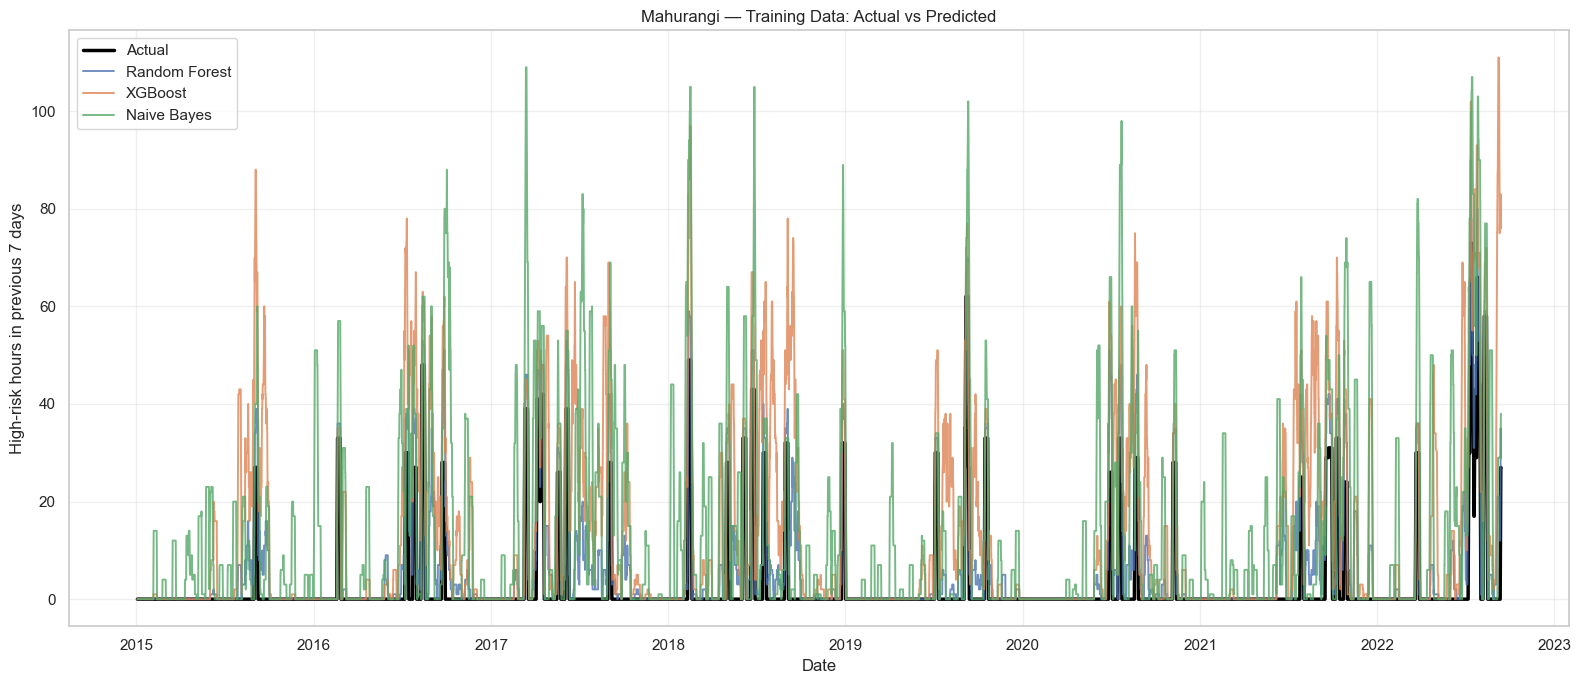

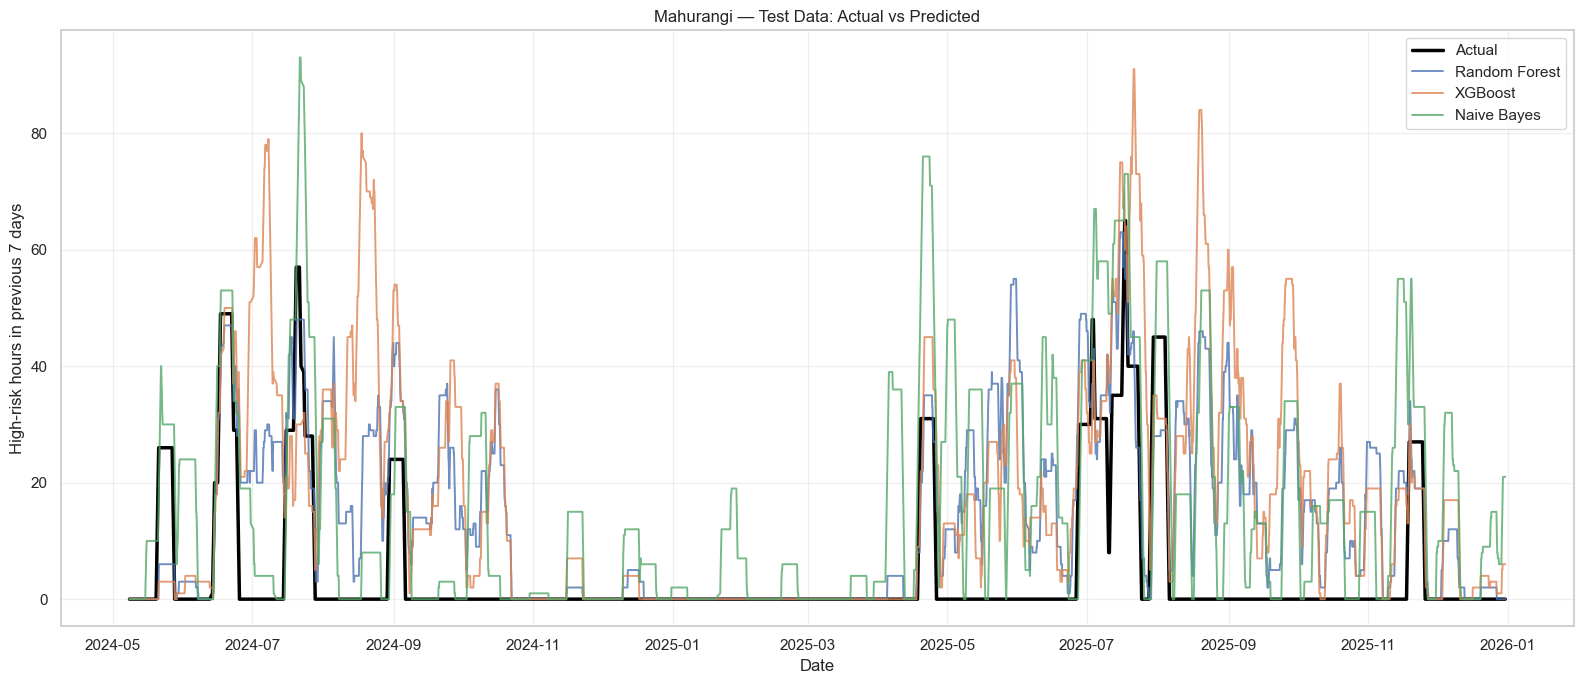

In [98]:
# Create predictions for training and test data

rf_threshold = float(selected_rf_threshold)
xgb_threshold = float(best_exact_f2_xgb["threshold"])
nb_threshold = float(selected_probability_threshold)

models = {
    "Random Forest": (random_forest_model, rf_threshold),
    "XGBoost": (xgboost_model, xgb_threshold),
    "Naive Bayes": (naive_bayes_model, nb_threshold)
}

train_results = pd.DataFrame({
    "timestamp": pd.to_datetime(training_data["timestamp"]).reset_index(drop=True),
    "Actual": np.asarray(y_train)
}).set_index("timestamp")

test_results = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]).reset_index(drop=True),
    "Actual": np.asarray(y_test)
}).set_index("timestamp")

for model_name, (model, threshold) in models.items():

    train_probability = model.predict_proba(X_train)[:, 1]
    test_probability = model.predict_proba(X_test)[:, 1]

    train_results[model_name] = (
        train_probability >= threshold
    ).astype(int)

    test_results[model_name] = (
        test_probability >= threshold
    ).astype(int)

# Weekly rolling totals
train_weekly = train_results.rolling(168, min_periods=1).sum()
test_weekly = test_results.rolling(168, min_periods=1).sum()

# Training graph
plt.figure(figsize=(16, 7))

for column in train_weekly.columns:
    plt.plot(
        train_weekly.index,
        train_weekly[column],
        label=column,
        linewidth=2.5 if column == "Actual" else 1.4,
        color="black" if column == "Actual" else None,
        alpha=1 if column == "Actual" else 0.8
    )

plt.title("Mahurangi — Training Data: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("High-risk hours in previous 7 days")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Test graph
plt.figure(figsize=(16, 7))

for column in test_weekly.columns:
    plt.plot(
        test_weekly.index,
        test_weekly[column],
        label=column,
        linewidth=2.5 if column == "Actual" else 1.4,
        color="black" if column == "Actual" else None,
        alpha=1 if column == "Actual" else 0.8
    )

plt.title("Mahurangi — Test Data: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("High-risk hours in previous 7 days")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

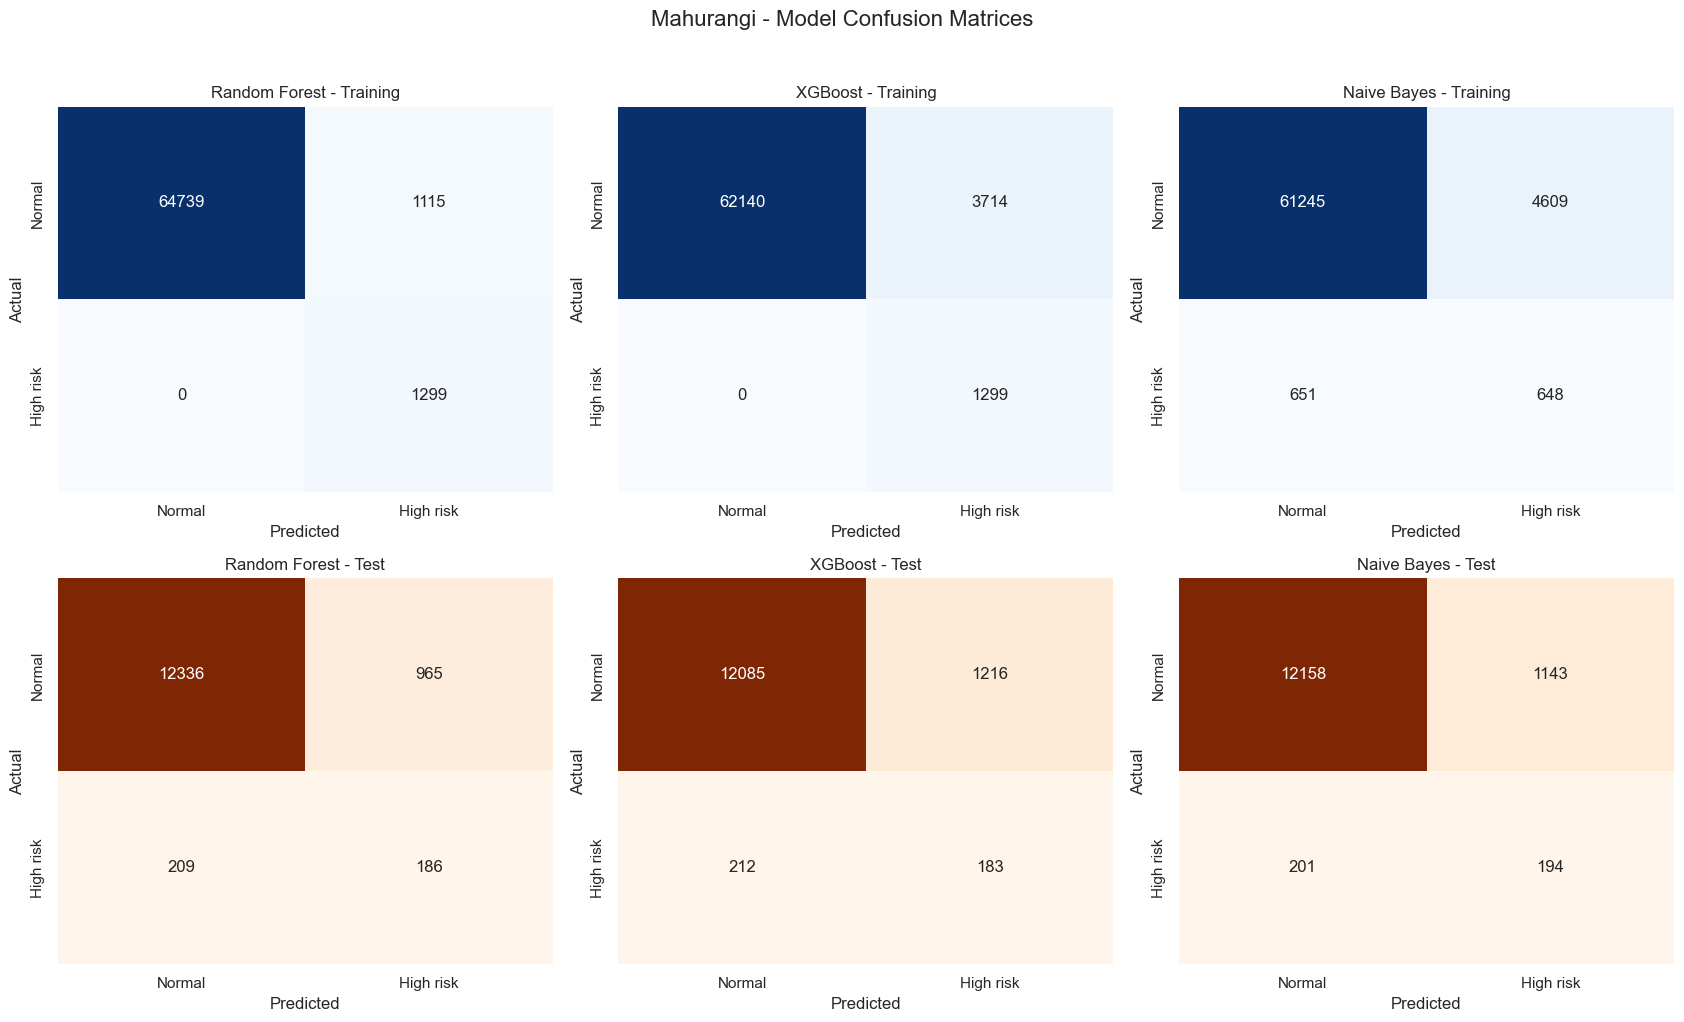

In [99]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for column_number, model_name in enumerate(models):

    train_matrix = confusion_matrix(
        train_results["Actual"],
        train_results[model_name]
    )

    test_matrix = confusion_matrix(
        test_results["Actual"],
        test_results[model_name]
    )

    sns.heatmap(
        train_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[0, column_number],
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"]
    )

    axes[0, column_number].set_title(f"{model_name} - Training")
    axes[0, column_number].set_xlabel("Predicted")
    axes[0, column_number].set_ylabel("Actual")

    sns.heatmap(
        test_matrix,
        annot=True,
        fmt="d",
        cmap="Oranges",
        cbar=False,
        ax=axes[1, column_number],
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"]
    )

    axes[1, column_number].set_title(f"{model_name} - Test")
    axes[1, column_number].set_xlabel("Predicted")
    axes[1, column_number].set_ylabel("Actual")

plt.suptitle(
    "Mahurangi - Model Confusion Matrices",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()